# Network Intrusion Detection System — UNSW-NB15: Live Anomaly Detection, HMM, Clustering and Transfer

**Team:** Bhabyam Kumar (142401013), Narahari Sai Rohan (142401026), Piyush Dubey (142401028), Abhishek Ganesh Iyer (112401002)

Notebook `ids_nsl_kdd.ipynb` covered NSL-KDD and ended with the HMM failing, because NSL-KDD rows have **no hosts and no timestamps**. This notebook adds a second public dataset, **UNSW-NB15**, whose raw flows have source/destination IPs, ports and start times. It covers the problem-statement claims that `ids_nsl_kdd` could not:
- integrating a second public dataset into the same pipeline,
- host-and-time anomaly detection on attacker machines the model has never seen,
- a **live** (streaming) replay with alerts, latency and throughput,
- an HMM on **real** time-ordered sequences (kept as the **sequence baseline**),
- gradient boosting vs the HMM on the same folds; the winners become `ids_unsw`'s **primary classifier and detector** (Task 11b),
- clustering to surface unknown attack groups,
- cross-dataset transfer, and risk tiers / decision support.

Most methods are reused from `IDS_Final.ipynb` (§9, §9a, §11, §12C, §12E-4), so the numbers match it where the setup is the same.

**Rule used everywhere:** choices and thresholds come from training hosts, validation hosts or shard 1 only. Held-out hosts and shards 2–4 are only used to report results.

**Dataset source:** UNSW-NB15, Moustafa & Slay (2015), UNSW Canberra Cyber Range Lab — https://research.unsw.edu.au/projects/unsw-nb15-dataset. The four raw CSV shards (`UNSW-NB15_1..4.csv`, about 2.5 million flows) and `NUSW-NB15_features.csv` go in `../data/raw/UNSW/`. They are larger than GitHub's 100 MB limit, so that folder is in `.gitignore` and has to be downloaded.

## Task 1 — Setup
*Source: Repo style + IDS_Final settings (§1).* Same seed, thread limit and HMM settings as IDS_Final, so the reused experiments give the same numbers.

In [1]:
import sys
import time
import json
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.special import logsumexp
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score,
                             balanced_accuracy_score, classification_report, f1_score,
                             normalized_mutual_info_score, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 42
CPU_THREADS = 2
HMM_ITERATIONS = 30
HMM_STATES = 4
HMM_SYMBOLS = 20
SEQUENCE_LENGTH = 20
SESSION_GAP_SECONDS = 60
MAX_HMM_SEQUENCES_PER_CLASS = 1500
HOST_WINDOW_SECONDS = 60
KNN_REFERENCE = 20000
FA_BUDGET = 0.05

try:
    from threadpoolctl import threadpool_limits
    THREAD_LIMIT = threadpool_limits(limits=CPU_THREADS)
except ImportError:
    THREAD_LIMIT = None

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

print("Python version:", sys.version.split()[0])
for library in ["numpy", "pandas", "scipy", "sklearn", "matplotlib"]:
    print(f"  {library}: {__import__(library).__version__}")

RUN_STARTED = time.time()
UNSW_DIR = "../data/raw/UNSW/"

Python version: 3.12.15
  numpy: 2.4.0
  pandas: 2.3.3
  scipy: 1.17.0
  sklearn: 1.8.0
  matplotlib: 3.10.8


## Task 2 — Load the Raw UNSW-NB15 Shards
*Source: IDS_Final §9 / §12C loaders.* The raw shards have no header; the 49 column names come from `NUSW-NB15_features.csv`. We keep the fields needed for hosts and time (`srcip`, `dstip`, `dsport`, `stime`) plus traffic features. Addresses, times and labels are **never** model features. (The smaller `training-set`/`testing-set` CSVs drop IPs and times, so they can't be used for host or sequence work.)

In [2]:
feature_list = pd.read_csv(UNSW_DIR + "NUSW-NB15_features.csv", encoding="latin-1")
RAW_COLUMNS = [name.strip().lower().replace(" ", "") for name in feature_list["Name"]]
print("Columns from the feature list:", len(RAW_COLUMNS))

UNSW_NUMERIC = ["dur", "sbytes", "dbytes", "spkts", "dpkts", "sttl", "dttl", "sload", "dload",
                "smeansz", "dmeansz", "sloss", "dloss"]
LOAD_COLUMNS = ["srcip", "dstip", "dsport", "proto", "state", "service", "stime", "sintpkt",
                "attack_cat", "label"] + UNSW_NUMERIC
SHARDS = ["UNSW-NB15_1.csv", "UNSW-NB15_2.csv", "UNSW-NB15_3.csv", "UNSW-NB15_4.csv"]


def load_shard(name):
    flows = pd.read_csv(UNSW_DIR + name, header=None, names=RAW_COLUMNS, usecols=LOAD_COLUMNS,
                        encoding="utf-8-sig", dtype={"srcip": str, "dstip": str, "dsport": str}, low_memory=False)
    flows = flows[[c for c in RAW_COLUMNS if c in LOAD_COLUMNS]]
    flows["attack_cat"] = flows["attack_cat"].fillna("Normal").astype(str).str.strip().replace("", "Normal")
    flows["attack_cat"] = flows["attack_cat"].replace({"Backdoor": "Backdoors"})
    for column in UNSW_NUMERIC + ["stime", "sintpkt", "label"]:
        flows[column] = pd.to_numeric(flows[column], errors="coerce").fillna(0)
    flows.loc[flows["label"] == 0, "attack_cat"] = "Normal"
    return flows


shards = {}
for name in SHARDS:
    start = time.perf_counter()
    shards[name] = load_shard(name)
    print(f"{name}: {len(shards[name]):,} flows ({time.perf_counter() - start:.1f}s)", flush=True)

raw = shards["UNSW-NB15_1.csv"]           # shard 1 = the development shard (as in IDS_Final)
assert set(raw["label"].unique()) == {0, 1}
assert (raw[UNSW_NUMERIC].to_numpy() >= 0).all()
print("Total flows in the 4 shards:", f"{sum(len(s) for s in shards.values()):,}")

Columns from the feature list: 49


UNSW-NB15_1.csv: 700,001 flows (1.9s)


UNSW-NB15_2.csv: 700,001 flows (1.7s)


UNSW-NB15_3.csv: 700,001 flows (1.6s)


UNSW-NB15_4.csv: 440,044 flows (1.0s)


Total flows in the 4 shards: 2,540,047


## Task 3 — Exploratory Analysis of UNSW-NB15
*Source: Repo `01_eda` style (counts, crosstabs) applied to UNSW.* We look at size, imbalance, time span and which hosts attack, because the later tasks split by host and by time.

In [3]:
overview = []
for name, flows in shards.items():
    overview.append({"shard": name, "flows": len(flows), "attack_share_%": 100 * flows["label"].mean(),
                     "source_hosts": flows["srcip"].nunique(),
                     "attacker_hosts": flows.loc[flows["label"] == 1, "srcip"].nunique(),
                     "start (UTC)": pd.to_datetime(flows["stime"].min(), unit="s"),
                     "end (UTC)": pd.to_datetime(flows["stime"].max(), unit="s")})
display(pd.DataFrame(overview).round(2))

all_attackers = sorted(set().union(*[set(f.loc[f["label"] == 1, "srcip"]) for f in shards.values()]))
print("Source hosts that send attack flows (all shards):", all_attackers)

category_counts = pd.DataFrame({name: f["attack_cat"].value_counts() for name, f in shards.items()}).fillna(0).astype(int)
category_counts["total"] = category_counts.sum(axis=1)
display(category_counts.sort_values("total", ascending=False))

,shard,flows,attack_share_%,source_hosts,attacker_hosts,start (UTC),end (UTC)
0,UNSW-NB15_1.csv,700001,3.17,40,4,2015-01-22 11:49:37,2015-01-22 19:44:02
1,UNSW-NB15_2.csv,700001,7.54,40,4,2015-01-22 19:43:15,2015-02-18 03:45:29
2,UNSW-NB15_3.csv,700001,22.49,40,4,2015-02-18 03:44:59,2015-02-18 09:00:09
3,UNSW-NB15_4.csv,440044,20.20,38,4,2015-02-18 08:59:44,2015-02-18 12:21:08


Source hosts that send attack flows (all shards): ['175.45.176.0', '175.45.176.1', '175.45.176.2', '175.45.176.3']


,UNSW-NB15_1.csv,UNSW-NB15_2.csv,UNSW-NB15_3.csv,UNSW-NB15_4.csv,total
attack_cat,,,,,
Normal,677786,647252,542576,351150,2218764
Generic,7522,27883,118198,61878,215481
Exploits,5409,11103,16574,11439,44525
Fuzzers,5051,4668,9137,5390,24246
DoS,1167,4637,5642,4907,16353
Reconnaissance,1759,3116,5582,3530,13987
Analysis,526,608,873,670,2677
Backdoors,534,370,759,666,2329
Shellcode,223,324,593,371,1511


Protocol and service by category (shard 1). Generic attacks are mostly UDP/DNS, Exploits target HTTP/FTP/SMTP — different families leave different traffic shapes, which clustering (Task 9) relies on.

In [ ]:
print("Protocol within each categry (% of shard-1 flows):")
top_protocols = raw["proto"].value_counts().index[:4]
print((pd.crosstab(raw["attack_cat"], raw["proto"].where(raw["proto"].isin(top_protocols), "other"),
                   normalize="index") * 100).round(1))

print("\nTop services per attack category (shard 1):")
for category in sorted(set(raw["attack_cat"]) - {"Normal"}):
    services = raw.loc[raw["attack_cat"] == category, "service"].value_counts().head(3)
    print(f"  {category:15s}", {k: int(v) for k, v in services.items()})

Protocol within each category (% of shard-1 flows):


proto           arp  ospf  other   tcp   udp
attack_cat                                  
Analysis        0.0   1.1   87.8  11.0   0.0
Backdoors       0.0   3.0   88.4   7.7   0.9
DoS             0.0   4.8   46.3  41.4   7.5
Exploits        0.0   0.9   18.5  78.1   2.6
Fuzzers         0.0   1.2   18.4  61.4  19.0
Generic         0.0   0.1    0.3   5.9  93.8
Normal          0.6   0.3    0.0  71.6  27.5
Reconnaissance  0.0   0.8    0.7  57.9  40.6
Shellcode       0.0   0.0    0.0  49.8  50.2
Worms           0.0   0.0    0.0  87.5  12.5

Top services per attack category (shard 1):
  Analysis        {'-': 526}
  Backdoors       {'-': 526, 'http': 7, 'ftp': 1}


  DoS             {'-': 905, 'http': 184, 'smtp': 37}
  Exploits        {'-': 3038, 'http': 1202, 'smtp': 517}
  Fuzzers         {'-': 4610, 'ftp': 246, 'http': 182}


  Generic         {'dns': 6932, '-': 351, 'http': 172}
  Reconnaissance  {'-': 1533, 'http': 207, 'snmp': 11}
  Shellcode       {'-': 223}


  Worms           {'http': 17, '-': 7}


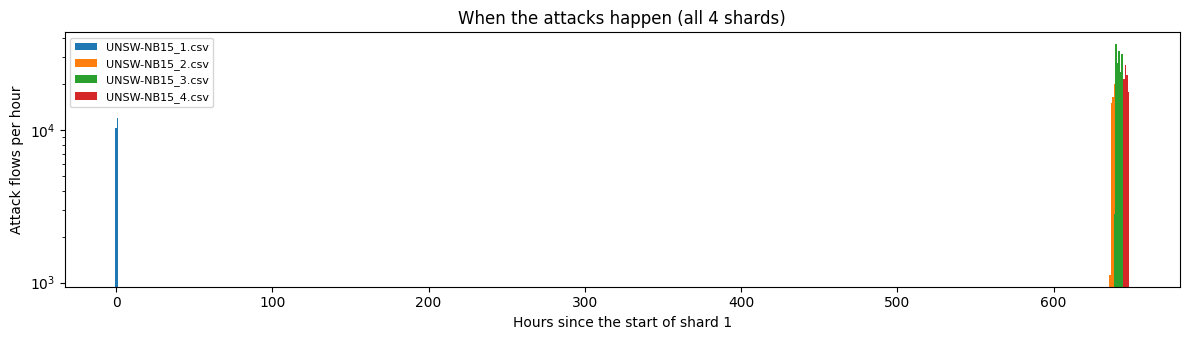

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for name, flows in shards.items():
    hours = ((flows["stime"] - shards[SHARDS[0]]["stime"].min()) // 3600).astype(int)
    per_hour = flows.groupby(hours)["label"].sum()
    ax.bar(per_hour.index, per_hour.values, width=1.0, label=name)
ax.set(xlabel="Hours since the start of shard 1", ylabel="Attack flows per hour", yscale="log",
       title="When the attacks happen (all 4 shards)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**UNSW-NB15 vs NSL-KDD.** Only two families line up (`DoS`, and `Reconnaissance` ≈ `Probe`). Seven UNSW categories are **new** compared with NSL-KDD's four families, and UNSW has the host/time fields that NSL-KDD lacks.

In [6]:
category_map = pd.DataFrame([
    ("Reconnaissance", "Probe"), ("DoS", "DoS"), ("Exploits", "closest: R2L / U2R"), ("Backdoors", "closest: R2L"),
    ("Shellcode", "closest: U2R"), ("Worms", "none (new)"), ("Fuzzers", "none (new)"),
    ("Analysis", "none (new)"), ("Generic", "none (new)")], columns=["UNSW-NB15 category", "NSL-KDD family"])
category_map["flows (all shards)"] = category_map["UNSW-NB15 category"].map(category_counts["total"]).astype(int)
display(category_map)

comparison_fields = pd.DataFrame({
    "NSL-KDD": ["125,973 / 22,544", "41", "no", "no", "4 families"],
    "UNSW-NB15 raw": [f"{sum(len(s) for s in shards.values()):,} flows", "47 + labels", "yes (srcip/dstip/ports)",
                      "yes (stime/ltime)", "9 categories"]},
    index=["rows", "features", "host addresses", "timestamps", "attack labels"])
display(comparison_fields)

,UNSW-NB15 category,NSL-KDD family,flows (all shards)
0,Reconnaissance,Probe,13987
1,DoS,DoS,16353
2,Exploits,closest: R2L / U2R,44525
3,Backdoors,closest: R2L,2329
4,Shellcode,closest: U2R,1511
5,Worms,none (new),174
6,Fuzzers,none (new),24246
7,Analysis,none (new),2677
8,Generic,none (new),215481


,NSL-KDD,UNSW-NB15 raw
rows,"125,973 / 22,544","2,540,047 flows"
features,41,47 + labels
host addresses,no,yes (srcip/dstip/ports)
timestamps,no,yes (stime/ltime)
attack labels,4 families,9 categories


## Task 4 — Flow Features and Real Time-Ordered Sequences
*Source: IDS_Final §9.* Flow features: log of 13 traffic counters + one-hot protocol and state (no IPs, times or labels). Sequences: flows of one **source → destination pair**, sorted by `stime`, cut into 20-flow windows, and split when two flows are more than 60 s apart. These are real sequences, which NSL-KDD never had.

In [7]:
def unsw_features(frame, numeric=UNSW_NUMERIC):
    blocks = [np.log1p(frame[numeric].to_numpy(dtype=np.float64))]
    for column, levels in [("proto", ["tcp", "udp", "icmp"]), ("state", ["CON", "INT", "FIN", "REQ", "RST"])]:
        values = frame[column].astype(str).to_numpy()
        blocks.append(np.column_stack([values == value for value in levels] + [~np.isin(values, levels)]))
    return np.column_stack(blocks).astype(np.float32)


unsw_X = unsw_features(raw)
UNSW_FAMILIES = ["Normal"] + sorted(set(raw["attack_cat"]) - {"Normal"})
unsw_y = pd.Categorical(raw["attack_cat"], categories=UNSW_FAMILIES).codes

windows, window_hosts, tied_steps = [], [], 0
ordered = raw.sort_values(["srcip", "dstip", "stime"], kind="stable")
for (source_host, destination_host), group in ordered.groupby(["srcip", "dstip"], sort=False):
    indices = group.index.to_numpy()
    gaps = np.diff(group["stime"].to_numpy())
    tied_steps += int((gaps == 0).sum())
    boundaries = np.r_[0, np.flatnonzero(gaps > SESSION_GAP_SECONDS) + 1, len(indices)]
    for start, stop in zip(boundaries[:-1], boundaries[1:]):
        usable = (stop - start) // SEQUENCE_LENGTH * SEQUENCE_LENGTH
        if usable:
            block = indices[start:start + usable].reshape(-1, SEQUENCE_LENGTH)
            windows.extend(block)
            window_hosts.extend([source_host] * len(block))

windows = np.asarray(windows, dtype=np.int64)
window_hosts = np.asarray(window_hosts)
window_attack = raw["label"].to_numpy()[windows].any(axis=1).astype(int)
window_states = unsw_y[windows]
assert np.unique(windows).size == windows.size
assert np.all(np.diff(raw["stime"].to_numpy()[windows], axis=1) >= 0)

attack_hosts = sorted(raw.loc[raw["label"] == 1, "srcip"].unique())
usable_hosts = sorted(np.unique(window_hosts))
benign_hosts = sorted(set(usable_hosts) - set(attack_hosts))
print({"raw_rows": len(raw), "windows": len(windows), "attack_windows": int(window_attack.sum()),
       "benign_windows": int((window_attack == 0).sum()), "source_hosts": len(usable_hosts),
       "attack_source_hosts": len(attack_hosts), "retained_fraction": round(windows.size / len(raw), 4)})

{'raw_rows': 700001, 'windows': 34271, 'attack_windows': 906, 'benign_windows': 33365, 'source_hosts': 19, 'attack_source_hosts': 4, 'retained_fraction': 0.9792}


## Task 5 — Held-Out Attacker Hosts (the validation design for UNSW)
*Source: IDS_Final §9a.* There are 4 attacker hosts. Each one is held out once as the **test** attacker, the next one is the **validation** attacker, and the benign hosts are rotated into disjoint train / validation / test groups. A detector is therefore always tested on an attacker machine it has never seen — the UNSW version of 06's leave-attack-type-out folds.

In [8]:
benign_order = np.random.default_rng(SEED).permutation(benign_hosts)
benign_groups = np.array_split(benign_order, len(attack_hosts))


def host_partition(fold):
    held_out_host = attack_hosts[fold]
    validation_host = attack_hosts[(fold + 1) % len(attack_hosts)]
    test_hosts = set(benign_groups[fold]) | {held_out_host}
    validation_hosts = set(benign_groups[(fold + 1) % len(attack_hosts)]) | {validation_host}
    training_hosts = set(usable_hosts) - test_hosts - validation_hosts
    assert training_hosts.isdisjoint(test_hosts | validation_hosts) and test_hosts.isdisjoint(validation_hosts)
    return held_out_host, training_hosts, validation_hosts, test_hosts


for fold in range(len(attack_hosts)):
    held_out_host, tr_hosts, va_hosts, te_hosts = host_partition(fold)
    print(f"Fold {fold}: test attacker {held_out_host} | train/val/test hosts {len(tr_hosts)}/{len(va_hosts)}/{len(te_hosts)}")

Fold 0: test attacker 175.45.176.0 | train/val/test hosts 9/5/5
Fold 1: test attacker 175.45.176.1 | train/val/test hosts 9/5/5
Fold 2: test attacker 175.45.176.2 | train/val/test hosts 10/4/5
Fold 3: test attacker 175.45.176.3 | train/val/test hosts 10/5/4


Shared helpers from IDS_Final: metrics at a threshold, and a threshold that maximises validation F1 with validation false alarms ≤ 5%.

In [9]:
def binary_summary(truth, score, threshold):
    truth = np.asarray(truth, dtype=int)
    predicted = np.asarray(score) >= threshold
    p, r, f, _ = precision_recall_fscore_support(truth, predicted, average="binary", zero_division=0)
    return dict(precision=float(p), recall=float(r), f1=float(f), accuracy=float(accuracy_score(truth, predicted)),
                normal_fpr=float(predicted[truth == 0].mean()), roc_auc=float(roc_auc_score(truth, score)),
                average_precision=float(average_precision_score(truth, score)),
                support=len(truth), attack_windows=int(truth.sum()), threshold=float(threshold))


def validation_threshold(truth, score, max_fpr=0.05):
    truth, score = np.asarray(truth, dtype=int), np.asarray(score)
    candidates = np.unique(np.r_[np.quantile(score, np.linspace(0, 1, 151)), np.nextafter(score.max(), np.inf)])
    metrics = [(float(f1_score(truth, score >= t, zero_division=0)), float(np.mean(score[truth == 0] >= t)), float(t))
               for t in candidates]
    eligible = [m for m in metrics if m[1] <= max_fpr]
    return max(eligible, key=lambda m: (m[0], -m[1], m[2]))[2]


def shuffle_observations(observations, seed):
    permutation = np.argsort(np.random.default_rng(seed).random(observations.shape), axis=1)
    return np.take_along_axis(observations, permutation, axis=1)


def normal_percentile(reference, values):
    return np.searchsorted(np.sort(reference), values, side="right") / len(reference)


def budget_threshold(reference_scores, budget):
    return float(np.quantile(reference_scores, 1 - budget))


def split_normal(rows, seed, holdout=0.15):
    rows = np.random.default_rng(seed).permutation(rows)
    cut = int(round(holdout * len(rows)))
    return rows[cut:], rows[:cut]

## Task 6 — Hidden Markov Model on Real UNSW Sequences (sequence baseline)
*Source: IDS_Final (from-scratch categorical HMM, same class as notebook `ids_nsl_kdd`) and §9a (experiment).* Flows become 20 symbols (train-only scaling + k-means). Two 4-state HMMs are trained with Baum–Welch, one on benign windows and one on attack windows; the score is their log-likelihood ratio. **Controls:** the same HMMs on shuffled windows (5 seeds), a no-transition symbol model, and a per-flow gradient-boosting classifier. A supervised HMM also labels each flow's UNSW category using its neighbours.

The HMM is kept because the problem statement asks for it. It is the **sequence baseline**: Task 11b compares it with gradient boosting on the same folds, and the better model becomes the primary one. Validation-host scores are stored here for that choice; they do not change any test number.

In [10]:
class CategoricalHMM:
    """Categorical HMM for a batch of equal-length sequences (log-space, Baum-Welch, Viterbi)."""

    def __init__(self, n_states, n_symbols, seed=42, smoothing=1e-6):
        self.n_states = n_states
        self.n_symbols = n_symbols
        self.seed = seed
        self.smoothing = smoothing

    @staticmethod
    def normalize(values):
        return values / values.sum(axis=-1, keepdims=True)

    def forward(self, x):
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        alpha = np.empty_like(emissions)
        log_transition = np.log(self.transition_)
        alpha[:, 0] = np.log(self.start_) + emissions[:, 0]
        for t in range(1, x.shape[1]):
            alpha[:, t] = emissions[:, t] + logsumexp(alpha[:, t - 1, :, None] + log_transition[None], axis=1)
        return alpha, emissions, logsumexp(alpha[:, -1], axis=1)

    def score(self, x):
        return self.forward(np.asarray(x))[2]

    def fit(self, x, max_iter=30, tolerance=1e-4):
        # Baum-Welch (EM)
        x = np.asarray(x)
        rng = np.random.default_rng(self.seed)
        k = self.n_states
        self.start_ = rng.dirichlet(np.ones(k))
        self.transition_ = np.vstack([rng.dirichlet(np.ones(k) + 3 * np.eye(k)[j]) for j in range(k)])
        self.emission_ = rng.dirichlet(np.ones(self.n_symbols), size=k)
        self.history_ = [float(self.score(x).sum())]
        self.converged_ = False
        for iteration in range(max_iter):
            alpha, emissions, likelihood = self.forward(x)
            beta = np.zeros_like(alpha)
            log_transition = np.log(self.transition_)
            for t in range(x.shape[1] - 2, -1, -1):
                beta[:, t] = logsumexp(log_transition[None] + emissions[:, t + 1, None, :] + beta[:, t + 1, None, :], axis=2)
            gamma = np.exp(alpha + beta - likelihood[:, None, None])
            transitions = np.full((k, k), self.smoothing)
            for t in range(x.shape[1] - 1):
                transitions += np.exp(alpha[:, t, :, None] + log_transition[None] + emissions[:, t + 1, None, :]
                                      + beta[:, t + 1, None, :] - likelihood[:, None, None]).sum(axis=0)
            emission_counts = np.vstack([np.bincount(x.ravel(), weights=gamma[:, :, j].ravel(), minlength=self.n_symbols)
                                         for j in range(k)]) + self.smoothing
            self.start_ = self.normalize(gamma[:, 0].sum(axis=0) + self.smoothing)
            self.transition_ = self.normalize(transitions)
            self.emission_ = self.normalize(emission_counts)
            self.history_.append(float(self.score(x).sum()))
            change = (self.history_[-1] - self.history_[-2]) / x.size
            if -1e-8 <= change < tolerance:
                self.converged_ = True
                break
        self.iterations_ = iteration + 1
        return self

    def fit_supervised(self, x, states):
        k, s = self.n_states, self.n_symbols
        self.start_ = self.normalize(np.bincount(states[:, 0], minlength=k) + self.smoothing)
        transitions = np.full((k, k), self.smoothing)
        np.add.at(transitions, (states[:, :-1].ravel(), states[:, 1:].ravel()), 1)
        emissions = np.full((k, s), self.smoothing)
        np.add.at(emissions, (states.ravel(), x.ravel()), 1)
        self.transition_ = self.normalize(transitions)
        self.emission_ = self.normalize(emissions)
        self.state_prior_ = self.normalize(np.bincount(states.ravel(), minlength=k) + self.smoothing)
        return self

    def decode(self, x):
        # Viterbi
        x = np.asarray(x)
        emissions = np.log(self.emission_[:, x]).transpose(1, 2, 0)
        n, length = x.shape
        delta = np.log(self.start_) + emissions[:, 0]
        previous = np.zeros((n, length, self.n_states), dtype=np.int64)
        for t in range(1, length):
            scores = delta[:, :, None] + np.log(self.transition_)[None]
            previous[:, t] = scores.argmax(axis=1)
            delta = scores.max(axis=1) + emissions[:, t]
        path = np.empty((n, length), dtype=np.int64)
        path[:, -1] = delta.argmax(axis=1)
        for t in range(length - 1, 0, -1):
            path[:, t - 1] = previous[np.arange(n), t, path[:, t]]
        return path

    def emission_only(self, x):
        return (np.log(self.emission_[:, np.asarray(x)]) + np.log(self.state_prior_)[:, None, None]).argmax(axis=0)


def best_hmm(observations, seed):
    # two restarts, chosen by training likelihood only
    candidates = [CategoricalHMM(HMM_STATES, HMM_SYMBOLS, seed + offset).fit(observations, max_iter=HMM_ITERATIONS)
                  for offset in (0, 101)]
    return max(candidates, key=lambda model: model.history_[-1])


check = CategoricalHMM(2, 2)
check.start_ = np.array([0.6, 0.4])
check.transition_ = np.array([[0.7, 0.3], [0.2, 0.8]])
check.emission_ = np.array([[0.9, 0.1], [0.3, 0.7]])
toy = np.array([[0, 1, 1], [1, 0, 1]])
for sequence, likelihood, path in zip(toy, np.exp(check.score(toy)), check.decode(toy)):
    probabilities = {}
    for states in itertools.product(range(2), repeat=len(sequence)):
        p = check.start_[states[0]] * check.emission_[states[0], sequence[0]]
        for t in range(1, len(sequence)):
            p *= check.transition_[states[t - 1], states[t]] * check.emission_[states[t], sequence[t]]
        probabilities[states] = p
    assert np.isclose(likelihood, sum(probabilities.values()))
    assert tuple(path) == max(probabilities, key=probabilities.get)
print("HMM checks passed: forward likelihood and Viterbi match brute force.")

HMM checks passed: forward likelihood and Viterbi match brute force.


In [11]:
sequence_rows, stage_rows, fold_audits = [], [], []
hmm_validation_rows = []        # validation-host scores, used in Task 11b to pick the primary model
fold_symbols = {}

for fold in range(len(attack_hosts)):
    held_out_host, training_hosts, validation_hosts, test_hosts = host_partition(fold)
    tr_w = np.flatnonzero(np.isin(window_hosts, list(training_hosts)))
    va_w = np.flatnonzero(np.isin(window_hosts, list(validation_hosts)))
    te_w = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
    rng = np.random.default_rng(SEED + fold)
    train_flows = windows[tr_w].ravel()
    fit_flows = rng.choice(train_flows, size=min(60000, len(train_flows)), replace=False)
    symbol_scaler = StandardScaler().fit(unsw_X[fit_flows])
    symbol_cluster = MiniBatchKMeans(n_clusters=HMM_SYMBOLS, batch_size=4096, n_init=3, random_state=SEED + fold)
    symbol_cluster.fit(symbol_scaler.transform(unsw_X[fit_flows]))
    observations = symbol_cluster.predict(symbol_scaler.transform(unsw_X))[windows]

    sampled = {}
    for label in [0, 1]:
        ids = tr_w[window_attack[tr_w] == label]
        sampled[label] = rng.choice(ids, size=min(MAX_HMM_SEQUENCES_PER_CLASS, len(ids)), replace=False)
    normal_hmm = best_hmm(observations[sampled[0]], SEED + 10 * fold)
    attack_hmm = best_hmm(observations[sampled[1]], SEED + 10 * fold + 1)

    def hmm_score(obs):
        return (attack_hmm.score(obs) - normal_hmm.score(obs)) / SEQUENCE_LENGTH

    threshold = validation_threshold(window_attack[va_w], hmm_score(observations[va_w]))
    hmm_test = hmm_score(observations[te_w])
    hmm_validation = binary_summary(window_attack[va_w], hmm_score(observations[va_w]), threshold)
    row = binary_summary(window_attack[te_w], hmm_test, threshold)
    sequence_rows.append({**row, "fold": fold, "model": "HMM", "test_attack_host": held_out_host})

    shuffle_metrics = [binary_summary(window_attack[te_w], hmm_score(shuffle_observations(observations[te_w], s)), threshold)
                       for s in [42, 43, 44, 45, 46]]
    shuffled_row = {key: float(np.mean([m[key] for m in shuffle_metrics])) for key in shuffle_metrics[0]}
    sequence_rows.append({**shuffled_row, "fold": fold, "model": "HMM shuffled (5-seed mean)", "test_attack_host": held_out_host})

    iid = {}
    for label in [0, 1]:
        counts = np.bincount(observations[sampled[label]].ravel(), minlength=HMM_SYMBOLS) + 1
        iid[label] = counts / counts.sum()
    log_ratio = np.log(iid[1]) - np.log(iid[0])
    iid_threshold = validation_threshold(window_attack[va_w], log_ratio[observations[va_w]].mean(axis=1))
    iid_row = binary_summary(window_attack[te_w], log_ratio[observations[te_w]].mean(axis=1), iid_threshold)
    sequence_rows.append({**iid_row, "fold": fold, "model": "IID symbols (no transitions)", "test_attack_host": held_out_host})

    flow_model = HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=15, learning_rate=0.08,
                                                class_weight="balanced", random_state=SEED + fold)
    flow_model.fit(unsw_X[fit_flows], raw["label"].to_numpy()[fit_flows])
    flow_va = flow_model.predict_proba(unsw_X[windows[va_w].ravel()])[:, 1].reshape(-1, SEQUENCE_LENGTH).max(axis=1)
    flow_te = flow_model.predict_proba(unsw_X[windows[te_w].ravel()])[:, 1].reshape(-1, SEQUENCE_LENGTH).max(axis=1)
    flow_row = binary_summary(window_attack[te_w], flow_te, validation_threshold(window_attack[va_w], flow_va))
    sequence_rows.append({**flow_row, "fold": fold, "model": "Independent-flow booster", "test_attack_host": held_out_host})

    stage_hmm = CategoricalHMM(len(UNSW_FAMILIES), HMM_SYMBOLS, smoothing=0.5)
    stage_hmm.fit_supervised(observations[tr_w], window_states[tr_w])
    for name, prediction in [("Category HMM", stage_hmm.decode(observations[te_w])),
                             ("Category emission-only", stage_hmm.emission_only(observations[te_w]))]:
        stage_rows.append({"fold": fold, "model": name,
                           "accuracy": accuracy_score(window_states[te_w].ravel(), prediction.ravel()),
                           "balanced_accuracy": balanced_accuracy_score(window_states[te_w].ravel(), prediction.ravel()),
                           "macro_f1": f1_score(window_states[te_w].ravel(), prediction.ravel(),
                                                labels=np.arange(len(UNSW_FAMILIES)), average="macro", zero_division=0)})
    hmm_validation_rows.append({"fold": fold, "model": "HMM", "setting": -1,
                                "val_macro_f1": f1_score(window_states[va_w].ravel(), stage_hmm.decode(observations[va_w]).ravel(),
                                                         labels=np.arange(len(UNSW_FAMILIES)), average="macro", zero_division=0),
                                "val_roc_auc": hmm_validation["roc_auc"], "val_average_precision": hmm_validation["average_precision"],
                                "val_f1": hmm_validation["f1"]})
    if fold == 0:
        first_fold_transition = stage_hmm.transition_.copy()
    print(f"Fold {fold + 1}/{len(attack_hosts)}: HMM AUC {row['roc_auc']:.3f}, F1 {row['f1']:.3f}, "
          f"FPR {row['normal_fpr']:.3f}; flow booster AUC {flow_row['roc_auc']:.3f}", flush=True)

sequence_results = pd.DataFrame(sequence_rows)
stage_results = pd.DataFrame(stage_rows)
metric_columns = ["roc_auc", "average_precision", "precision", "recall", "f1", "normal_fpr"]
hmm_summary = sequence_results.groupby("model")[metric_columns].mean()
print("Mean over the 4 held-out attacker hosts:")
display(hmm_summary.round(4))
display(stage_results.groupby("model")[["accuracy", "macro_f1"]].mean().round(4))
folds_better = int((stage_results.query("model == 'Category HMM'")["macro_f1"].to_numpy()
                    > stage_results.query("model == 'Category emission-only'")["macro_f1"].to_numpy()).sum())
print(f"Category HMM beats emission-only on macro F1 in {folds_better}/{len(attack_hosts)} folds")

Fold 1/4: HMM AUC 0.998, F1 0.785, FPR 0.007; flow booster AUC 0.999


Fold 2/4: HMM AUC 1.000, F1 0.958, FPR 0.005; flow booster AUC 0.999


Fold 3/4: HMM AUC 0.957, F1 0.239, FPR 0.044; flow booster AUC 0.979


Fold 4/4: HMM AUC 0.997, F1 0.812, FPR 0.005; flow booster AUC 0.999


Mean over the 4 held-out attacker hosts:


,roc_auc,average_precision,precision,recall,f1,normal_fpr
model,,,,,,
HMM,0.9880,0.6634,0.6178,0.9114,0.6983,0.0153
HMM shuffled (5-seed mean),0.9880,0.6614,0.6170,0.9109,0.6981,0.0153
IID symbols (no transitions),0.9881,0.6669,0.6642,0.8814,0.7180,0.0141
Independent-flow booster,0.9939,0.8803,0.7165,0.8192,0.6765,0.0125


,accuracy,macro_f1
model,,
Category HMM,0.9639,0.1775
Category emission-only,0.9677,0.1244


Category HMM beats emission-only on macro F1 in 4/4 folds


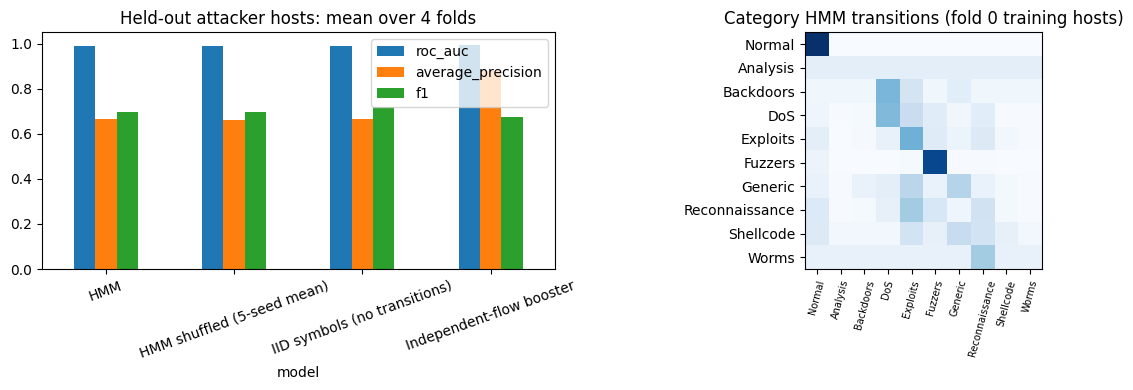

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hmm_summary[["roc_auc", "average_precision", "f1"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Held-out attacker hosts: mean over 4 folds")
axes[0].set_ylim(0, 1.05)
axes[1].imshow(first_fold_transition, cmap="Blues", vmin=0, vmax=1)
axes[1].set(xticks=range(len(UNSW_FAMILIES)), yticks=range(len(UNSW_FAMILIES)), yticklabels=UNSW_FAMILIES,
            title="Category HMM transitions (fold 0 training hosts)")
axes[1].set_xticklabels(UNSW_FAMILIES, rotation=75, fontsize=7)
plt.tight_layout()
plt.savefig("../results/ids_unsw_hmm_unsw.png", dpi=120)
plt.show()

**What the HMM shows on real data.**
- It detects held-out attackers very well (high AUC), so the HMM *works* on UNSW, unlike on NSL-KDD.
- But ordered and shuffled windows score almost the same, and the no-transition model matches it: **detection comes from which flows appear, not from their order.** The per-flow booster is as good or better.
- **Where order helps:** labelling each flow's category. The category HMM (using neighbours) beats emission-only on macro F1 in the folds counted above, because attack categories come in runs (Exploits next to Exploits, Fuzzers next to Fuzzers).
- **Role from here on:** sequence baseline. Task 11b shows that class-weighted gradient boosting beats it on these same folds.

## Task 7 — Host-and-Time Anomaly Detection on Unseen Attacker Hosts
*Source: IDS_Final §12C + §12E-4.* Every **source host** is summarised **minute by minute** (flows, distinct destinations/ports, bytes, durations, TTL, protocol and state shares, gaps). Detectors (Isolation Forest, kNN distance, their mean) are trained on **benign hosts only**; the score with the best validation PR AUC is used and the alarm threshold is a **5% false-alarm budget on validation benign hosts**. Test hosts are never used for fitting or thresholds.

**Honest headline = without TTL.** In UNSW-NB15 the attacker machines use very different TTL values (a testbed artefact), which makes detection unrealistically easy. The with-TTL result is kept only for comparison.

In [13]:
def host_time_windows(flows):
    f = flows.assign(minute=(flows["stime"] // HOST_WINDOW_SECONDS).astype(np.int64),
                     tcp=flows["proto"].eq("tcp"), udp=flows["proto"].eq("udp"),
                     st_fin=flows["state"].eq("FIN"), st_con=flows["state"].eq("CON"), st_int=flows["state"].eq("INT"),
                     st_req=flows["state"].eq("REQ"), no_service=flows["service"].astype(str).str.strip().eq("-"),
                     log_sbytes=np.log1p(flows["sbytes"]), log_dbytes=np.log1p(flows["dbytes"]))
    grouped = f.groupby(["srcip", "minute"], sort=True)
    table = grouped.agg(flows=("stime", "size"), dst_hosts=("dstip", "nunique"), dst_ports=("dsport", "nunique"),
                        sbytes=("sbytes", "sum"), dbytes=("dbytes", "sum"), mean_log_sbytes=("log_sbytes", "mean"),
                        mean_log_dbytes=("log_dbytes", "mean"), mean_dur=("dur", "mean"), max_dur=("dur", "max"),
                        mean_sttl=("sttl", "mean"), mean_dttl=("dttl", "mean"), mean_sintpkt=("sintpkt", "mean"),
                        tcp=("tcp", "mean"), udp=("udp", "mean"), st_fin=("st_fin", "mean"), st_con=("st_con", "mean"),
                        st_int=("st_int", "mean"), st_req=("st_req", "mean"), no_service=("no_service", "mean"),
                        first=("stime", "min"), last=("stime", "max"),
                        attack=("label", "max"), attack_flows=("label", "sum")).reset_index()
    table["mean_gap"] = (table["last"] - table["first"]) / (table["flows"] - 1).clip(lower=1)
    return table, grouped.ngroup().to_numpy()


HOST_FEATURES = ["flows", "dst_hosts", "dst_ports", "sbytes", "dbytes", "mean_log_sbytes", "mean_log_dbytes",
                 "mean_dur", "max_dur", "mean_sttl", "mean_dttl", "mean_sintpkt", "tcp", "udp", "st_fin",
                 "st_con", "st_int", "st_req", "no_service", "mean_gap"]
LOG_FEATURES = ["flows", "dst_hosts", "dst_ports", "sbytes", "dbytes", "mean_dur", "max_dur", "mean_sintpkt", "mean_gap"]
NO_TTL_FEATURES = [c for c in HOST_FEATURES if c not in ["mean_sttl", "mean_dttl"]]
HOST_CANDIDATES = ["Isolation forest", "kNN distance", "Mean of two"]


def host_matrix(table, columns):
    m = table[columns].astype(float).copy()
    logged = [c for c in LOG_FEATURES if c in columns]
    m[logged] = np.log1p(m[logged].clip(lower=0))
    return m.to_numpy(np.float64)


def fit_host_scorers(normal_matrix, seed):
    scaler = StandardScaler().fit(normal_matrix)
    Zn = scaler.transform(normal_matrix)
    iso = IsolationForest(n_estimators=200, n_jobs=CPU_THREADS, random_state=seed).fit(Zn)
    reference = Zn[np.random.default_rng(seed).choice(len(Zn), min(KNN_REFERENCE, len(Zn)), replace=False)]
    knn = NearestNeighbors(n_neighbors=5, n_jobs=CPU_THREADS).fit(reference)
    return {"Isolation forest": lambda M: -iso.score_samples(scaler.transform(M)),
            "kNN distance": lambda M: knn.kneighbors(scaler.transform(M))[0].mean(axis=1)}


def host_percentiles(scorers, M_reference, M_target):
    # scores turned into "percentile of benign reference windows" so detectors can be averaged
    out = {}
    for name in ["Isolation forest", "kNN distance"]:
        ref = scorers[name](M_reference)
        out[name] = (normal_percentile(ref, ref), normal_percentile(ref, scorers[name](M_target)))
    out["Mean of two"] = tuple((out["Isolation forest"][i] + out["kNN distance"][i]) / 2 for i in (0, 1))
    return out


start = time.perf_counter()
hw, flow_hw = host_time_windows(raw)
hw_attack = hw["attack"].to_numpy().astype(int)
hw_host = hw["srcip"].to_numpy()
shard_tables = {name: host_time_windows(shards[name])[0] for name in SHARDS[1:]}
print({"shard1_host_minutes": len(hw), "attack_minutes": int(hw_attack.sum()), "source_hosts": hw["srcip"].nunique(),
       "median_flows_per_window": float(hw["flows"].median())})
print(f"Host-minute tables for 4 shards built in {time.perf_counter() - start:.1f}s")

{'shard1_host_minutes': 8632, 'attack_minutes': 469, 'source_hosts': 40, 'median_flows_per_window': 104.0}
Host-minute tables for 4 shards built in 1.8s


In [14]:
def host_detector_folds(columns):
    M = host_matrix(hw, columns)
    fold_rows, pair_rows, chosen = [], [], []
    for fold in range(len(attack_hosts)):
        held_out_host, _, validation_hosts, test_hosts = host_partition(fold)
        fit_w = np.flatnonzero(~np.isin(hw_host, list(test_hosts | validation_hosts | set(attack_hosts))))
        val_w = np.flatnonzero(np.isin(hw_host, list(validation_hosts)))
        val_benign = val_w[np.isin(hw_host[val_w], benign_hosts)]
        test_w = np.flatnonzero(np.isin(hw_host, list(test_hosts)))
        assert hw_attack[fit_w].sum() == 0
        pct = host_percentiles(fit_host_scorers(M[fit_w], SEED + fold), M[val_benign], M)
        best = max(HOST_CANDIDATES, key=lambda n: average_precision_score(hw_attack[val_w], pct[n][1][val_w]))
        chosen.append(best)
        ref, score = pct[best]
        row = binary_summary(hw_attack[test_w], score[test_w], np.nextafter(budget_threshold(ref, FA_BUDGET), np.inf))
        fold_rows.append({**row, "fold": fold, "test_attack_host": held_out_host, "score_used": best})
        te_pairs = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
        pair_score = score[flow_hw[windows[te_pairs]]].max(axis=1)
        pair_rows.append({"fold": fold, "roc_auc": roc_auc_score(window_attack[te_pairs], pair_score),
                          "average_precision": average_precision_score(window_attack[te_pairs], pair_score)})

    # later capture days: detector fitted on shard-1 benign hosts, 5% threshold from held-out shard-1 benign minutes
    final_score = pd.Series(chosen).mode().iloc[0]
    fit_part, ref_part = split_normal(np.flatnonzero(~np.isin(hw_host, attack_hosts)), SEED)
    shard_scorers = fit_host_scorers(M[fit_part], SEED)
    shard_rows = []
    for shard, table in shard_tables.items():
        truth = table["attack"].to_numpy().astype(int)
        ref, score = host_percentiles(shard_scorers, M[ref_part], host_matrix(table, columns))[final_score]
        row = binary_summary(truth, score, np.nextafter(budget_threshold(ref, FA_BUDGET), np.inf))
        shard_rows.append({**row, "shard": shard, "score_used": final_score,
                           "attack_hosts": int(table.loc[truth == 1, "srcip"].nunique())})
    return pd.DataFrame(fold_rows), pd.DataFrame(pair_rows), pd.DataFrame(shard_rows)


nottl_folds, nottl_pairs, nottl_shards = host_detector_folds(NO_TTL_FEATURES)
ttl_folds, ttl_pairs, ttl_shards = host_detector_folds(HOST_FEATURES)

print("WITHOUT TTL (honest headline), per held-out attacker host:")
display(nottl_folds[["fold", "test_attack_host", "score_used", "support", "attack_windows", "roc_auc",
                     "average_precision", "precision", "recall", "f1", "normal_fpr"]].round(4))

host_cols = ["roc_auc", "average_precision", "precision", "recall", "normal_fpr"]
ttl_comparison = pd.DataFrame({"without TTL (headline)": nottl_folds[host_cols].mean(),
                               "with TTL (testbed artefact)": ttl_folds[host_cols].mean()}).T
ttl_comparison["window_auc_vs_HMM_windows"] = [nottl_pairs["roc_auc"].mean(), ttl_pairs["roc_auc"].mean()]
print("Mean over the 4 held-out attacker hosts:")
display(ttl_comparison.round(4))

WITHOUT TTL (honest headline), per held-out attacker host:


,fold,test_attack_host,score_used,support,attack_windows,roc_auc,average_precision,precision,recall,f1,normal_fpr
0,0,175.45.176.0,Mean of two,1961,117,0.9972,0.9355,0.4466,1.0000,0.6174,0.0786
1,1,175.45.176.1,Isolation forest,1939,118,0.8800,0.4904,0.6842,0.3305,0.4457,0.0099
2,2,175.45.176.2,kNN distance,1530,117,0.9685,0.5667,0.5735,1.0000,0.7290,0.0616
3,3,175.45.176.3,Isolation forest,1501,117,0.7401,0.1416,0.0444,0.0513,0.0476,0.0932


Mean over the 4 held-out attacker hosts:


,roc_auc,average_precision,precision,recall,normal_fpr,window_auc_vs_HMM_windows
without TTL (headline),0.8965,0.5336,0.4372,0.5954,0.0608,0.9838
with TTL (testbed artefact),0.9517,0.8008,0.4756,0.8120,0.0690,0.9968


**Per shard (later capture days, never used for fitting or thresholds).** This is the "does it keep working on new data" check.

In [15]:
shard_compare = pd.concat([nottl_shards.assign(features="without TTL"), ttl_shards.assign(features="with TTL")])
display(shard_compare.pivot_table(index="shard", columns="features",
                                  values=["roc_auc", "average_precision", "recall", "normal_fpr"]).round(4))

average_precision             normal_fpr               recall              roc_auc            
features                 with TTL without TTL   with TTL without TTL with TTL without TTL with TTL without TTL
shard                                                                                                         
UNSW-NB15_2.csv            0.9568      0.5863     0.0511      0.0470      1.0      0.7043   0.9979      0.9682
UNSW-NB15_3.csv            0.9429      0.6289     0.1080      0.0864      1.0      0.7775   0.9926      0.9362
UNSW-NB15_4.csv            0.9294      0.6148     0.1035      0.0915      1.0      0.7803   0.9907      0.9327

**Reading it.** Without TTL, the normal-only detector still ranks attack minutes well (AUC ≈ 0.9) on attacker machines it never saw, at a ~5–6% false-alarm rate. One attacker host (`175.45.176.3`) is hard to separate, which pulls the mean recall down. With TTL everything looks near-perfect — that is the testbed artefact, not real skill. On the later shards the false alarms drift above the 5% budget because benign traffic changes over time.

## Task 8 — LIVE Anomaly Detection: Streaming Replay of Unseen Days
*Source: new, built on the IDS_Final §12C host-minute detector.* We replay **shards 2–4** (about 1.8M flows from later capture days, never used for fitting) in `stime` order, as if they arrived live:
- flows are processed **minute by minute**; when a minute closes, each active host's window is summarised and scored, and an alert is emitted with its timestamp;
- the only state kept is **bounded**: the open minute's flows, plus per host a 10-minute score history and alert counters;
- the detector, the score choice and the 5% threshold all come from **shard 1 benign hosts** (no-TTL features, the honest setup).

We report alerts per hour, false-alarm rate, **detection latency** (first attack flow of a host → first alert) and **throughput** (flows/second).

In [16]:
from collections import deque

LIVE_SCORE = nottl_folds["score_used"].mode().iloc[0]          # chosen on validation hosts in Task 7
M1_live = host_matrix(hw, NO_TTL_FEATURES)
M1_ttl = host_matrix(hw, HOST_FEATURES)
live_fit, live_ref = split_normal(np.flatnonzero(~np.isin(hw_host, attack_hosts)), SEED)
live_scorers = fit_host_scorers(M1_live[live_fit], SEED)
ttl_scorers = fit_host_scorers(M1_ttl[live_fit], SEED)


def reference_scores(scorers, M_ref):
    return {name: np.sort(scorers[name](M_ref)) for name in ["Isolation forest", "kNN distance"]}


live_reference = reference_scores(live_scorers, M1_live[live_ref])
ttl_reference = reference_scores(ttl_scorers, M1_ttl[live_ref])


def percentile_score(scorers, reference, M, score_name):
    pct = {name: np.searchsorted(reference[name], scorers[name](M), side="right") / len(reference[name])
           for name in ["Isolation forest", "kNN distance"]}
    pct["Mean of two"] = (pct["Isolation forest"] + pct["kNN distance"]) / 2
    return pct[score_name]


ref_live = percentile_score(live_scorers, live_reference, M1_live[live_ref], LIVE_SCORE)
LIVE_THRESHOLD = budget_threshold(ref_live, FA_BUDGET)
TTL_SCORE = ttl_folds["score_used"].mode().iloc[0]
TTL_THRESHOLD = budget_threshold(percentile_score(ttl_scorers, ttl_reference, M1_ttl[live_ref], TTL_SCORE), FA_BUDGET)
print(f"Live detector: {LIVE_SCORE} (no TTL), threshold {LIVE_THRESHOLD:.4f} = 5% budget on held-out shard-1 benign minutes")

Live detector: Isolation forest (no TTL), threshold 0.9500 = 5% budget on held-out shard-1 benign minutes


In [17]:
stream = pd.concat([shards[name].assign(shard=name) for name in SHARDS[1:]], ignore_index=True)
stream = stream.sort_values("stime", kind="stable").reset_index(drop=True)
stream_minute = (stream["stime"] // HOST_WINDOW_SECONDS).astype(np.int64).to_numpy()
minute_values, minute_starts = np.unique(stream_minute, return_index=True)
minute_ends = np.r_[minute_starts[1:], len(stream)]
print(f"Stream: {len(stream):,} flows over {len(minute_values):,} active minutes "
      f"({pd.to_datetime(stream['stime'].min(), unit='s')} → {pd.to_datetime(stream['stime'].max(), unit='s')} UTC)")

host_state = {}            # bounded: one small record per host
alert_log, window_log = [], []
loop_start = time.perf_counter()

for minute, a, b in zip(minute_values, minute_starts, minute_ends):
    chunk = stream.iloc[a:b]
    table, _ = host_time_windows(chunk)              # windows for the minute that just closed
    score = percentile_score(live_scorers, live_reference, host_matrix(table, NO_TTL_FEATURES), LIVE_SCORE)
    score_ttl = percentile_score(ttl_scorers, ttl_reference, host_matrix(table, HOST_FEATURES), TTL_SCORE)
    emitted_at = (minute + 1) * HOST_WINDOW_SECONDS  # an alert can only be raised when the minute closes
    for host, s, s_ttl, flows, attack in zip(table["srcip"], score, score_ttl, table["flows"], table["attack"]):
        state = host_state.setdefault(host, {"recent": deque(maxlen=10), "alerts": 0, "first_alert": None})
        state["recent"].append(s)
        alert = s > LIVE_THRESHOLD
        if alert:
            state["alerts"] += 1
            state["first_alert"] = state["first_alert"] or emitted_at
            alert_log.append({"time": emitted_at, "host": host, "score": s, "flows": flows, "true_attack": attack})
        window_log.append((minute, host, s, s_ttl, alert, s_ttl > TTL_THRESHOLD, attack))

stream_seconds = time.perf_counter() - loop_start
windows_live = pd.DataFrame(window_log, columns=["minute", "host", "score", "score_ttl", "alert", "alert_ttl", "attack"])
alerts_live = pd.DataFrame(alert_log)
THROUGHPUT = len(stream) / stream_seconds
print(f"Replay finished in {stream_seconds:.1f}s → {THROUGHPUT:,.0f} flows/second "
      f"(feature building + scoring, one CPU-bound Python loop)")

# the streamed windows must equal the batch host-minute table
batch_table, _ = host_time_windows(stream)
assert len(batch_table) == len(windows_live)
assert np.allclose(np.sort(percentile_score(live_scorers, live_reference, host_matrix(batch_table, NO_TTL_FEATURES), LIVE_SCORE)),
                   np.sort(windows_live["score"].to_numpy()))
print("Check passed: streaming windows and scores equal the batch computation.")

Stream: 1,840,046 flows over 980 active minutes (2015-01-22 19:43:15 → 2015-02-18 12:21:08 UTC)


Replay finished in 26.2s → 70,113 flows/second (feature building + scoring, one CPU-bound Python loop)


Check passed: streaming windows and scores equal the batch computation.


Window-level results, alert volume and detection latency. Attack **episodes** = runs of one host's attack flows with gaps under 5 minutes (declared before looking at results).

In [18]:
def live_metrics(name, alert, score):
    truth = windows_live["attack"].to_numpy().astype(int)
    alert = np.asarray(alert)
    p, r, f, _ = precision_recall_fscore_support(truth, alert, average="binary", zero_division=0)
    active_hours = len(np.unique(windows_live["minute"] // 60))
    return {"setup": name, "host_minutes": len(truth), "attack_minutes": int(truth.sum()),
            "precision": p, "recall": r, "f1": f, "false_alarm_rate": float(alert[truth == 0].mean()),
            "roc_auc": roc_auc_score(truth, score), "pr_auc": average_precision_score(truth, score),
            "host_minutes_per_hour": len(truth) / active_hours, "alerts_per_hour": alert.sum() / active_hours, "false_alerts_per_hour": alert[truth == 0].sum() / active_hours}


live_table = pd.DataFrame([live_metrics("LIVE, no TTL (headline)", windows_live["alert"], windows_live["score"]),
                           live_metrics("LIVE, with TTL (testbed artefact)", windows_live["alert_ttl"], windows_live["score_ttl"])])
display(live_table.round(4))

attack_flows = stream.loc[stream["label"] == 1, ["srcip", "stime", "shard"]]
episode_rows = []
for host, group in attack_flows.groupby("srcip"):
    times = np.sort(group["stime"].to_numpy())
    cuts = np.r_[0, np.flatnonzero(np.diff(times) > 300) + 1, len(times)]
    host_alerts = np.sort(alerts_live.loc[alerts_live["host"] == host, "time"].to_numpy()) if len(alerts_live) else np.array([])
    for a, b in zip(cuts[:-1], cuts[1:]):
        start_t, end_t = times[a], times[b - 1]
        window_start = start_t // HOST_WINDOW_SECONDS * HOST_WINDOW_SECONDS
        hits = host_alerts[(host_alerts > window_start) & (host_alerts <= end_t + HOST_WINDOW_SECONDS)]
        episode_rows.append({"host": host, "start (UTC)": pd.to_datetime(start_t, unit="s"), "attack_flows": b - a,
                             "duration_min": (end_t - start_t) / 60, "detected": len(hits) > 0,
                             "latency_s": hits[0] - start_t if len(hits) else np.nan})
episodes = pd.DataFrame(episode_rows)

latency_summary = {
    "attack_episodes": len(episodes),
    "episodes_detected_%": 100 * episodes["detected"].mean(),
    "attack_flows_in_detected_episodes_%": 100 * episodes.loc[episodes["detected"], "attack_flows"].sum() / episodes["attack_flows"].sum(),
    "median_latency_s": episodes["latency_s"].median(),
    "p90_latency_s": episodes["latency_s"].quantile(0.9),
    "detected_within_2_min_%": 100 * np.mean(episodes["latency_s"] <= 120),
}
print("Detection latency (no TTL):", {k: round(float(v), 1) for k, v in latency_summary.items()})

first_attack = attack_flows.groupby("srcip")["stime"].min()
host_rows = []
for host, t0 in first_attack.items():
    host_alert_times = alerts_live.loc[alerts_live["host"] == host, "time"].to_numpy()
    after = host_alert_times[host_alert_times > t0]
    host_rows.append({"host": host, "first_attack_flow (UTC)": pd.to_datetime(t0, unit="s"),
                      "first_alert_after_it (UTC)": pd.to_datetime(after.min(), unit="s"),
                      "latency_s": after.min() - t0,
                      "alerts_before_first_attack_flow": int((host_alert_times <= t0).sum())})
print("Per attacker host: first attack flow in the stream → first alert")
display(pd.DataFrame(host_rows))

,setup,host_minutes,attack_minutes,precision,recall,f1,false_alarm_rate,roc_auc,pr_auc,host_minutes_per_hour,alerts_per_hour,false_alerts_per_hour
0,"LIVE, no TTL (headline)",18456,2737,0.6578,0.7614,0.7058,0.0690,0.9511,0.6148,971.3684,166.7368,57.0526
1,"LIVE, with TTL (testbed artefact)",18456,2737,0.6858,1.0000,0.8136,0.0798,0.9947,0.9426,971.3684,210.0526,66.0000


Detection latency (no TTL): {'attack_episodes': 16.0, 'episodes_detected_%': 100.0, 'attack_flows_in_detected_episodes_%': 100.0, 'median_latency_s': 56.0, 'p90_latency_s': 139.5, 'detected_within_2_min_%': 81.2}
Per attacker host: first attack flow in the stream → first alert


,host,first_attack_flow (UTC),first_alert_after_it (UTC),latency_s,alerts_before_first_attack_flow
0,175.45.176.0,2015-02-18 00:23:59,2015-02-18 00:25:00,61,0
1,175.45.176.1,2015-02-18 00:24:28,2015-02-18 00:25:00,32,0
2,175.45.176.2,2015-02-18 00:25:05,2015-02-18 00:26:00,55,1
3,175.45.176.3,2015-02-18 00:24:27,2015-02-18 00:25:00,33,0


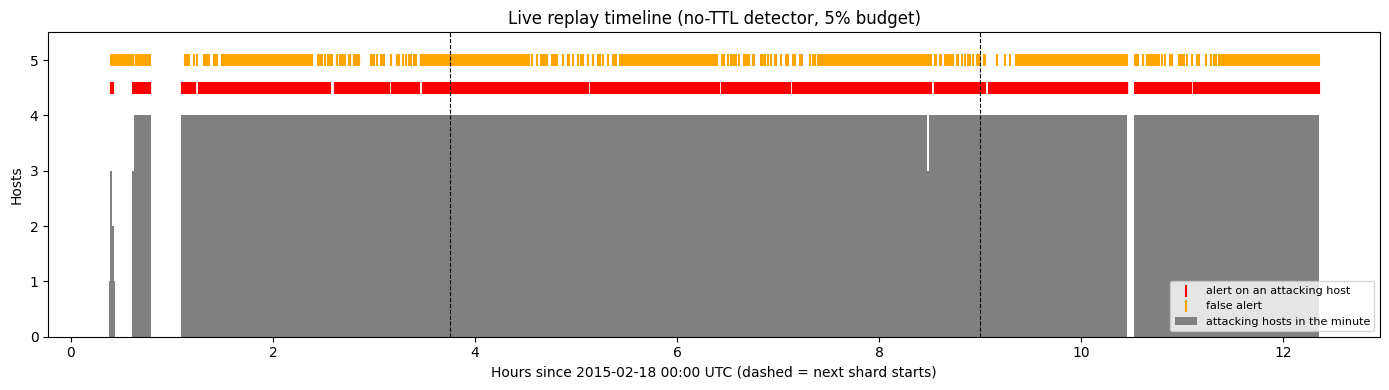

In [19]:
session = windows_live[windows_live["minute"] * 60 >= pd.Timestamp("2015-02-18").timestamp()]   # the long Feb-18 session
hours = (session["minute"] * 60 - pd.Timestamp("2015-02-18").timestamp()) / 3600
fig, ax = plt.subplots(figsize=(14, 4))
attacking = session.groupby(hours)["attack"].sum()
ax.bar(attacking.index, attacking.values, width=1 / 60, color="grey", label="attacking hosts in the minute")
true_alert = (session["alert"] & (session["attack"] == 1)).to_numpy()
false_alert = (session["alert"] & (session["attack"] == 0)).to_numpy()
ax.scatter(hours[true_alert], np.full(true_alert.sum(), 4.5), marker="|", color="red", s=80, label="alert on an attacking host")
ax.scatter(hours[false_alert], np.full(false_alert.sum(), 5.0), marker="|", color="orange", s=80, label="false alert")
for name in SHARDS[2:]:
    ax.axvline((shards[name]["stime"].min() - pd.Timestamp("2015-02-18").timestamp()) / 3600, ls="--", color="k", lw=0.8)
ax.set(xlabel="Hours since 2015-02-18 00:00 UTC (dashed = next shard starts)", ylabel="Hosts",
       title="Live replay timeline (no-TTL detector, 5% budget)", ylim=(0, 5.5))
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("../results/ids_unsw_live_timeline.png", dpi=120)
plt.show()

**Live result.** The replay runs much faster than real time: hours of recorded traffic take only seconds, so the engine can keep up with a real network. Each host is judged on 1-minute windows, so alerts arrive within about a minute of an attack starting. The alarm threshold was set on shard 1 to flag 5% of normal traffic. On the later shards the false-alarm rate is a little above that, because normal traffic changes slightly over the days (*drift*). About 970 host-minutes are checked every hour, so even a small error rate gives a large number of alerts per hour. Removing TTL, a shortcut that only works on this dataset, costs some missed attack minutes, and the with-TTL row shows that shortcut inflating the scores again. The engine replays flows that were already recorded, so it does not include capturing packets or turning them into flows.

## Task 9 — Clustering to Discover Attack Patterns Without Labels
*Source: IDS_Final §6 method (k-means, k by silhouette, purity / ARI / NMI) applied to UNSW attack flows; the repo's cluster profile table.* K-means is fitted on **shard 1 attack flows** (no TTL, no labels) and judged on **shards 2–4**. Purity is compared with the majority-class share, because `Generic` dominates the later shards.

In [20]:
NUMERIC_NO_TTL = [c for c in UNSW_NUMERIC if c not in ["sttl", "dttl"]]
later = stream                                            # shards 2-4, already concatenated in Task 8
attack_1 = raw[raw["label"] == 1]
attack_2 = later[later["label"] == 1]
cluster_scaler = StandardScaler().fit(unsw_features(attack_1, NUMERIC_NO_TTL))
C1 = cluster_scaler.transform(unsw_features(attack_1, NUMERIC_NO_TTL))
C2 = cluster_scaler.transform(unsw_features(attack_2, NUMERIC_NO_TTL))
silhouette_rows = np.random.default_rng(SEED).choice(len(C1), 4000, replace=False)


k_rows, k_models = [], {}
for k in range(4, 13):
    km = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=3, random_state=SEED).fit(C1)
    k_models[k] = km
    k_rows.append({"k": k, "silhouette_shard1": silhouette_score(C1[silhouette_rows], km.predict(C1[silhouette_rows]))})
k_table = pd.DataFrame(k_rows)
CLUSTER_K = int(k_table.loc[k_table["silhouette_shard1"].idxmax(), "k"])
attack_clusters = k_models[CLUSTER_K]
print("FROZEN k (best silhouette on shard 1):", CLUSTER_K)


def purity(labels, truth):
    table = pd.crosstab(labels, truth)
    return table.max(axis=1).sum() / len(truth)


labels_2 = attack_clusters.predict(C2)
truth_2 = attack_2["attack_cat"].to_numpy()
cluster_metrics = {"k": CLUSTER_K,
                   "purity_shards2_4": purity(labels_2, truth_2),
                   "majority_class_share": pd.Series(truth_2).value_counts(normalize=True).iloc[0],
                   "ARI": adjusted_rand_score(truth_2, labels_2),
                   "NMI": normalized_mutual_info_score(truth_2, labels_2)}
print({k: round(float(v), 4) for k, v in cluster_metrics.items()})

profile = pd.crosstab(pd.Series(labels_2, name="cluster"), pd.Series(truth_2, name="category"))
profile["size"] = profile.sum(axis=1)
profile["dominant"] = profile.drop(columns="size").idxmax(axis=1)
profile["purity"] = profile.drop(columns=["size", "dominant"]).max(axis=1) / profile["size"]
display(profile)

FROZEN k (best silhouette on shard 1): 7


{'k': 7.0, 'purity_shards2_4': 0.8159, 'majority_class_share': 0.6954, 'ARI': 0.814, 'NMI': 0.5099}


category,Analysis,Backdoors,DoS,Exploits,Fuzzers,Generic,Reconnaissance,Shellcode,Worms,size,dominant,purity
cluster,,,,,,,,,,,,
0,564,269,2313,19076,10665,2191,5942,639,123,41782,Exploits,0.456560
1,0,0,145,338,2402,527,0,347,12,3771,Fuzzers,0.636966
2,1521,1337,11003,13682,1588,1588,1885,0,0,32604,Exploits,0.419642
3,0,0,177,122,2174,202938,4173,302,6,209892,Generic,0.966869
4,58,118,726,1173,628,125,175,0,0,3003,Exploits,0.390609
5,0,13,458,4048,1706,475,2,0,7,6709,Exploits,0.603369
6,8,58,364,677,32,115,51,0,2,1307,Exploits,0.517980


Which categories form their **own** group? For each category: the cluster that holds most of its flows, how much of the category it captures (coverage) and how pure that cluster is. A category with high coverage and purity is a pattern an analyst would see as a separate group even without labels.

,category,flows,main_cluster,coverage,cluster_purity
5,Generic,207959,3,0.976,0.967
3,Exploits,39116,0,0.488,0.457
4,Fuzzers,19195,0,0.556,0.255
2,DoS,15186,2,0.725,0.337
6,Reconnaissance,12228,0,0.486,0.142
0,Analysis,2151,2,0.707,0.047
1,Backdoors,1795,2,0.745,0.041
7,Shellcode,1288,0,0.496,0.015
8,Worms,150,0,0.820,0.003


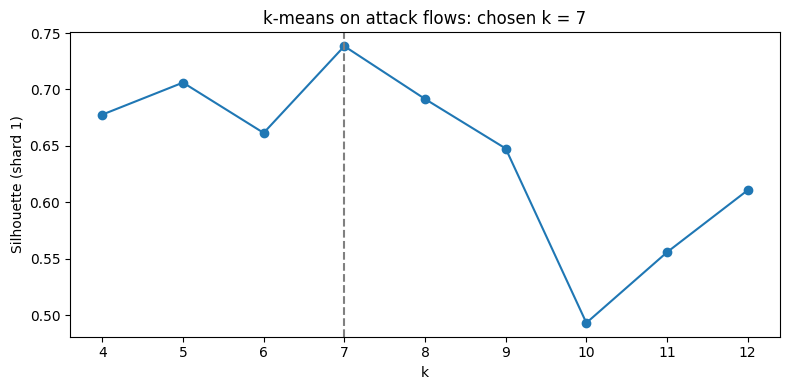

In [21]:
category_rows = []
for category in sorted(set(truth_2)):
    counts = profile[category] if category in profile else pd.Series(dtype=float)
    best = counts.idxmax()
    category_rows.append({"category": category, "flows": int(counts.sum()), "main_cluster": best,
                          "coverage": counts[best] / counts.sum(), "cluster_purity": counts[best] / profile.loc[best, "size"]})
category_groups = pd.DataFrame(category_rows).sort_values("flows", ascending=False)
display(category_groups.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
k_table.plot(x="k", y="silhouette_shard1", marker="o", ax=ax, legend=False)
ax.axvline(CLUSTER_K, ls="--", color="grey")
ax.set(ylabel="Silhouette (shard 1)", title=f"k-means on attack flows: chosen k = {CLUSTER_K}")
plt.tight_layout()
plt.show()

**Clustering live alerts for triage.** The alerts from the live replay (Task 8) are grouped with k-means on their host-minute features (k = 8, fixed in advance, no labels). If a cluster is almost all attack or almost all false alarms, an analyst can review or dismiss it as a group. This is how clustering surfaces **unknown** attack groups: the detector never saw these attackers.

In [22]:
batch_table["alert"] = batch_table.merge(windows_live[["minute", "host", "alert"]].rename(columns={"host": "srcip"}),
                                         on=["srcip", "minute"], how="left")["alert"].fillna(False).to_numpy()
alerted = batch_table[batch_table["alert"]].reset_index(drop=True)
alert_scaler = StandardScaler().fit(host_matrix(alerted, NO_TTL_FEATURES))
alert_clusters = MiniBatchKMeans(n_clusters=8, batch_size=4096, n_init=3, random_state=SEED)
alerted["alert_cluster"] = alert_clusters.fit_predict(alert_scaler.transform(host_matrix(alerted, NO_TTL_FEATURES)))

triage = alerted.groupby("alert_cluster").agg(alerts=("attack", "size"), attack_share=("attack", "mean"),
                                              hosts=("srcip", "nunique"), median_flows=("flows", "median"),
                                              median_dst_ports=("dst_ports", "median"))
display(triage.round(3))
pure = triage[(triage["attack_share"] >= 0.9) | (triage["attack_share"] <= 0.1)]
triage_summary = {"alerts": len(alerted),
                  "alerts_in_pure_clusters_%": 100 * pure["alerts"].sum() / len(alerted),
                  "attack_alerts_in_mostly_attack_clusters_%": 100 * alerted.loc[alerted["alert_cluster"].isin(triage.index[triage["attack_share"] >= 0.9]), "attack"].sum() / alerted["attack"].sum(),
                  "alert_cluster_purity": purity(alerted["alert_cluster"], alerted["attack"])}
print({k: round(float(v), 3) for k, v in triage_summary.items()})

,alerts,attack_share,hosts,median_flows,median_dst_ports
alert_cluster,,,,,
0,561,0.955,21,46.0,8.0
1,450,0.002,19,369.0,1.0
2,382,0.000,9,1.0,1.0
3,348,1.000,3,538.5,8.0
4,890,0.980,16,16.0,7.0
5,91,0.121,19,6.0,2.0
6,124,0.000,7,2.0,1.0
7,322,0.981,9,49.5,9.0


{'alerts': 3168.0, 'alerts_in_pure_clusters_%': 97.128, 'attack_alerts_in_mostly_attack_clusters_%': 99.424, 'alert_cluster_purity': 0.981}


**Weak approach, kept as one row: flow-level novelty.** Hide one attack category from shard 1, fit k-means on the known flows, and flag later flows that are farther from every centre than 99% of known flows. Averaged over the held-out categories:

In [23]:
rng = np.random.default_rng(SEED)
known_normal = rng.choice(np.flatnonzero(raw["label"].to_numpy() == 0), 60000, replace=False)
known_attack = np.flatnonzero(raw["label"].to_numpy() == 1)
later_rows = np.r_[rng.choice(np.flatnonzero(later["label"].to_numpy() == 0), 100000, replace=False),
                   np.flatnonzero(later["label"].to_numpy() == 1)]
F1_all = unsw_features(raw, NUMERIC_NO_TTL)
F2_all = unsw_features(later.iloc[later_rows], NUMERIC_NO_TTL)
y1_all, y2_all = raw["attack_cat"].to_numpy(), later["attack_cat"].to_numpy()[later_rows]
novelty_rows = []
for held_out in ["Generic", "Exploits", "Fuzzers", "DoS", "Reconnaissance", "Analysis", "Backdoors", "Shellcode"]:
    known = np.r_[known_normal, known_attack[y1_all[known_attack] != held_out]]
    scaler_k = StandardScaler().fit(F1_all[known])
    km = MiniBatchKMeans(n_clusters=20, batch_size=4096, n_init=3, random_state=SEED).fit(scaler_k.transform(F1_all[known]))
    limit = np.quantile(km.transform(scaler_k.transform(F1_all[known])).min(axis=1), 0.99)
    distance = km.transform(scaler_k.transform(F2_all)).min(axis=1)
    is_new, is_normal = y2_all == held_out, y2_all == "Normal"
    novelty_rows.append({"held_out": held_out, "flagged_held_out": np.mean(distance[is_new] > limit),
                         "flagged_normal": np.mean(distance[is_normal] > limit),
                         "auc_vs_normal": roc_auc_score(is_new[is_new | is_normal], distance[is_new | is_normal])})
novelty = pd.DataFrame(novelty_rows)
novelty_summary = pd.DataFrame([{"approach": "Flow-level novelty (held-out category, k-means distance)",
                                 "mean_flagged_held_out": novelty["flagged_held_out"].mean(),
                                 "mean_flagged_normal": novelty["flagged_normal"].mean(),
                                 "mean_auc": novelty["auc_vs_normal"].mean(),
                                 "auc_range": f"{novelty['auc_vs_normal'].min():.2f}-{novelty['auc_vs_normal'].max():.2f}"}])
display(novelty_summary.round(3))
print("Weak: held-out categories look like other attacks at flow level, so unknown attackers are found at host-minute "
      "level (Tasks 7-8) and grouped by the alert clustering above.")

,approach,mean_flagged_held_out,mean_flagged_normal,mean_auc,auc_range
0,"Flow-level novelty (held-out category, k-means...",0.035,0.007,0.628,0.33-0.92


Weak: held-out categories look like other attacks at flow level, so unknown attackers are found at host-minute level (Tasks 7-8) and grouped by the alert clustering above.


## Task 10 — Cross-Dataset Transfer on a Shared Schema (NSL-KDD ↔ UNSW-NB15)
*Source: IDS_Final §11.* Both datasets are mapped to the fields they share: duration, source bytes, destination bytes, protocol and service (8 common services, the rest = `other`), with a binary label. A class-weighted gradient booster is trained on one and tested on the other, next to in-domain references. **Balanced accuracy** is used because UNSW is about 97% normal (0.5 = no better than always guessing one class).

In [24]:
nsl_columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
    "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
nsl_train = pd.read_csv("../data/raw/KDDTrain+.txt", sep="\t", header=None, names=nsl_columns)
nsl_test = pd.read_csv("../data/raw/KDDTest+2.txt", sep=",", header=None, names=nsl_columns)

SHARED_SERVICES = ["http", "ftp", "ftp_data", "smtp", "domain_u", "ssh", "pop_3", "IRC"]
UNSW_SERVICE_MAP = {"http": "http", "ftp": "ftp", "ftp-data": "ftp_data", "smtp": "smtp",
                    "dns": "domain_u", "ssh": "ssh", "pop3": "pop_3", "irc": "IRC"}


def shared_matrix(duration, src, dst, proto, service):
    proto = pd.Series(proto).astype(str).str.lower().to_numpy()
    service = pd.Series(service).astype(str).to_numpy()
    blocks = [np.log1p(np.column_stack([duration, src, dst]).astype(np.float64))]
    blocks.append(np.column_stack([proto == p for p in ["tcp", "udp", "icmp"]] + [~np.isin(proto, ["tcp", "udp", "icmp"])]))
    blocks.append(np.column_stack([service == s for s in SHARED_SERVICES] + [~np.isin(service, SHARED_SERVICES)]))
    return np.column_stack(blocks).astype(np.float32)


def nsl_shared(frame):
    return shared_matrix(frame["duration"], frame["src_bytes"], frame["dst_bytes"], frame["protocol_type"], frame["service"])


unsw_service = raw["service"].astype(str).str.strip().map(UNSW_SERVICE_MAP).fillna("other")
unsw_shared = shared_matrix(raw["dur"], raw["sbytes"], raw["dbytes"], raw["proto"], unsw_service)
unsw_label = raw["label"].to_numpy().astype(bool)
nsl_tr_shared, nsl_te_shared = nsl_shared(nsl_train), nsl_shared(nsl_test)
nsl_tr_label, nsl_te_label = (nsl_train["label"] != "normal").to_numpy(), (nsl_test["label"] != "normal").to_numpy()
u_fit, u_eval = train_test_split(np.arange(len(raw)), test_size=0.3, stratify=unsw_label, random_state=SEED)


def shared_model(matrix, labels):
    return HistGradientBoostingClassifier(class_weight="balanced", max_iter=200, learning_rate=0.08,
                                          random_state=SEED).fit(matrix, labels)


def transfer_row(direction, model, matrix, truth):
    predicted = model.predict(matrix)
    return {"direction": direction, "accuracy": accuracy_score(truth, predicted),
            "balanced_accuracy": balanced_accuracy_score(truth, predicted),
            "attack_recall": float(np.mean(predicted[truth])), "normal_fpr": float(np.mean(predicted[~truth])),
            "test_rows": len(truth)}


nsl_model = shared_model(nsl_tr_shared, nsl_tr_label)
unsw_model = shared_model(unsw_shared[u_fit], unsw_label[u_fit])
transfer_table = pd.DataFrame([
    transfer_row("NSL-KDD → NSL-KDD test (in-domain)", nsl_model, nsl_te_shared, nsl_te_label),
    transfer_row("NSL-KDD → UNSW-NB15 (cross-dataset)", nsl_model, unsw_shared[u_eval], unsw_label[u_eval]),
    transfer_row("UNSW-NB15 → UNSW-NB15 held-out (in-domain)", unsw_model, unsw_shared[u_eval], unsw_label[u_eval]),
    transfer_row("UNSW-NB15 → NSL-KDD test (cross-dataset)", unsw_model, nsl_te_shared, nsl_te_label),
])
display(transfer_table.round(4))

,direction,accuracy,balanced_accuracy,attack_recall,normal_fpr,test_rows
0,NSL-KDD → NSL-KDD test (in-domain),0.8255,0.8421,0.7221,0.0379,22544
1,NSL-KDD → UNSW-NB15 (cross-dataset),0.9026,0.4965,0.0629,0.0699,210001
2,UNSW-NB15 → UNSW-NB15 held-out (in-domain),0.9910,0.9919,0.9928,0.0091,210001
3,UNSW-NB15 → NSL-KDD test (cross-dataset),0.4872,0.5388,0.1664,0.0889,22544


**Lesson.** In-domain the shared fields work well, but across datasets balanced accuracy falls to about 0.5 in **both** directions: a detector learned on one network does not carry over to another. A real deployment has to be trained (or at least re-calibrated) on its own network's normal traffic — which is exactly what the normal-only host detector in Tasks 7–8 does.

## Task 11 — Naming the Attack: Supervised Category Classifier on UNSW
*Source: IDS_Final §5 approach (class-weighted gradient boosting, per-class report, ROC/PR) applied to UNSW flows.* Trained on **shard 1** (all attack flows + 100k sampled normal flows; no TTL, no IPs/times), tested on **all 1.84M flows of shards 2–4**. It gives each alert a category so it can get a risk tier. This is the first classifier. Task 11b compares it with other gradient-boosting variants and the HMM, then replaces it with the winners for the later tasks.

Category model trained and applied to 1,840,046 flows in 17.6s


                precision    recall  f1-score   support

        Normal      1.000     0.978     0.989   1540978
      Analysis      0.062     0.421     0.108      2151
     Backdoors      0.048     0.531     0.089      1795
           DoS      0.236     0.145     0.180     15186
      Exploits      0.777     0.448     0.568     39116
       Fuzzers      0.400     0.772     0.527     19195
       Generic      0.997     0.982     0.989    207959
Reconnaissance      0.712     0.785     0.747     12228
     Shellcode      0.090     0.696     0.160      1288
         Worms      0.198     0.527     0.288       150

      accuracy                          0.956   1840046
     macro avg      0.452     0.628     0.464   1840046
  weighted avg      0.978     0.956     0.964   1840046



{'accuracy': 0.956, 'macro_f1': 0.4645, 'attack_vs_normal_roc_auc': 0.9979, 'attack_vs_normal_pr_auc': 0.9881, 'attack_precision': 0.9, 'attack_recall': 0.9992}


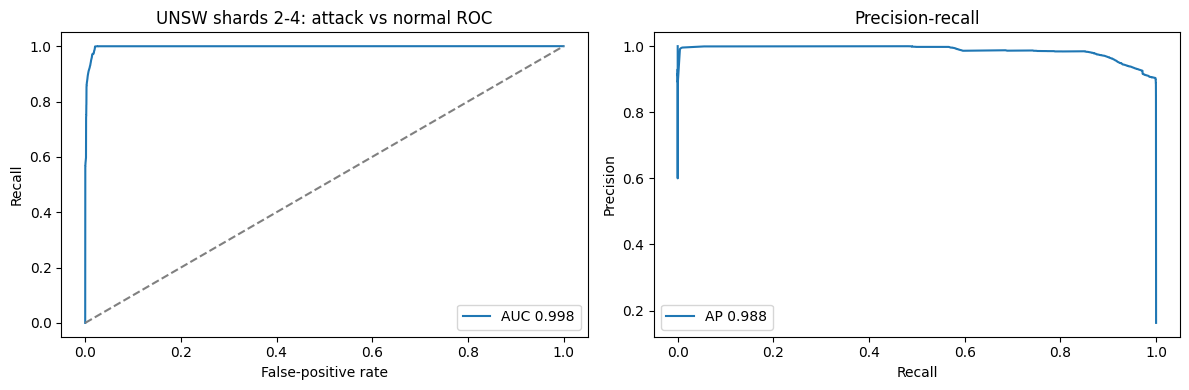

In [25]:
rng = np.random.default_rng(SEED)
normal_rows = np.flatnonzero(raw["label"].to_numpy() == 0)
train_rows = np.r_[rng.choice(normal_rows, 100000, replace=False), np.flatnonzero(raw["label"].to_numpy() == 1)]
category_model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_leaf_nodes=31,
                                                class_weight="balanced", random_state=SEED)
start = time.perf_counter()
category_model.fit(unsw_features(raw.iloc[train_rows], NUMERIC_NO_TTL), raw["attack_cat"].to_numpy()[train_rows])
later_proba = category_model.predict_proba(unsw_features(later, NUMERIC_NO_TTL))
later_pred = category_model.classes_[later_proba.argmax(axis=1)]
later_attack_score = 1 - later_proba[:, list(category_model.classes_).index("Normal")]
print(f"Category model trained and applied to {len(later):,} flows in {time.perf_counter() - start:.1f}s")

truth_later = later["attack_cat"].to_numpy()
print(classification_report(truth_later, later_pred, labels=UNSW_FAMILIES, digits=3, zero_division=0))
flow_is_attack = later["label"].to_numpy() == 1
category_summary = {"accuracy": accuracy_score(truth_later, later_pred),
                    "macro_f1": f1_score(truth_later, later_pred, labels=UNSW_FAMILIES, average="macro", zero_division=0),
                    "attack_vs_normal_roc_auc": roc_auc_score(flow_is_attack, later_attack_score),
                    "attack_vs_normal_pr_auc": average_precision_score(flow_is_attack, later_attack_score),
                    "attack_precision": precision_recall_fscore_support(flow_is_attack, later_pred != "Normal", average="binary")[0],
                    "attack_recall": precision_recall_fscore_support(flow_is_attack, later_pred != "Normal", average="binary")[1]}
print({k: round(float(v), 4) for k, v in category_summary.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fpr, tpr, _ = roc_curve(flow_is_attack, later_attack_score)
precision, recall, _ = precision_recall_curve(flow_is_attack, later_attack_score)
axes[0].plot(fpr, tpr, label=f"AUC {category_summary['attack_vs_normal_roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False-positive rate", ylabel="Recall", title="UNSW shards 2-4: attack vs normal ROC")
axes[1].plot(recall, precision, label=f"AP {category_summary['attack_vs_normal_pr_auc']:.3f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Task 11b — Gradient Boosting vs the HMM: Choosing the Primary Classifier and Detector
*Source: new; IDS_Final §5 boosting recipe on the Task 6 folds.* The problem statement asks for an HMM, so Task 6 keeps it, but that does not make it the best model for naming or catching attacks. Here a class-weighted `HistGradientBoostingClassifier` is trained on the **same held-out attacker-host folds, the same 20-flow windows and the same validation hosts as the HMM**, so the numbers line up row for row.
- One 10-class model per fold gives both jobs: the attack score is 1 − P(Normal) (a window scores as its riskiest flow, like the flow booster in Task 6), and the category is the arg-max.
- Training rows: every attack flow of the training hosts + 60k sampled normal flows (same size as the HMM's symbol sample).
- Two settings (small/large trees) and the alert threshold (best validation F1 with false alarms ≤ 5%, as for the HMM) are picked on **validation hosts only**.

Three feature sets:
- **(a) per-flow, no TTL** — the honest flow features (same as Task 11).
- **(b) (a) + host history, no TTL** — for each flow, what its source host did in the **last 1 and 5 minutes**: flows, bytes, distinct destination ports and hosts. Built per host in `stime` order, using only the current and earlier flows, so it is causal and can run live. This is the "sequence" idea without an HMM.
- **(c) per-flow with TTL** — reference only. These are the flow features the HMM symbols use, but TTL is a testbed artefact (Task 7), so (c) can never be chosen.

In [26]:
HISTORY_WINDOWS = [60, 300]
HISTORY_NAMES = [f"{kind}_last_{w}s" for w in HISTORY_WINDOWS for kind in ["flows", "bytes", "distinct_dst_ports", "distinct_dst_hosts"]]


def host_history_features(frame):
    """For every flow: what its source host did in the last 1 and 5 minutes, up to and including this flow.
    Flows are visited in stime order per host (file order breaks ties), so only the past is used."""
    n = len(frame)
    host = pd.factorize(frame["srcip"])[0].astype(np.int64)
    stime = frame["stime"].to_numpy(np.int64)
    order = np.lexsort((np.arange(n), stime, host))
    key = host[order] * 10**11 + stime[order]                      # host blocks, time-sorted inside each block
    total_bytes = (frame["sbytes"].to_numpy(np.float64) + frame["dbytes"].to_numpy(np.float64))[order]
    cumulative = np.r_[0.0, np.cumsum(total_bytes)]
    items = {"ports": pd.factorize(frame["dsport"].astype(str))[0][order].tolist(),
             "hosts": pd.factorize(frame["dstip"].astype(str))[0][order].tolist()}
    position = np.arange(n)
    columns = []
    for seconds in HISTORY_WINDOWS:
        start = np.searchsorted(key, key - seconds, side="right")   # first flow of the same host inside (t - W, t]
        distinct = {}
        for name, values in items.items():
            counts, left, out, starts = {}, 0, np.empty(n, dtype=np.int64), start.tolist()
            for i in range(n):
                value = values[i]
                counts[value] = counts.get(value, 0) + 1
                while left < starts[i]:
                    old = values[left]
                    if counts[old] == 1:
                        del counts[old]
                    else:
                        counts[old] -= 1
                    left += 1
                out[i] = len(counts)
            distinct[name] = out
        columns += [position - start + 1, cumulative[position + 1] - cumulative[start], distinct["ports"], distinct["hosts"]]
    history = np.empty((n, len(columns)), dtype=np.float32)
    history[order] = np.log1p(np.column_stack(columns))
    return history


# brute-force check on a small slice: recount every window directly from the past flows of the same host
check = raw.iloc[:3000]
fast = np.expm1(host_history_features(check))
positions = np.arange(len(check))
for row in np.random.default_rng(SEED).choice(len(check), 200, replace=False):
    me = check.iloc[row]
    same_host = (check["srcip"] == me["srcip"]).to_numpy()
    st = check["stime"].to_numpy()
    seen = same_host & ((st < me["stime"]) | ((st == me["stime"]) & (positions <= row)))   # strictly earlier, or same second and earlier in file
    for j, seconds in enumerate(HISTORY_WINDOWS):
        w = check[seen & (st > me["stime"] - seconds)]
        expected = [len(w), (w["sbytes"] + w["dbytes"]).sum(), w["dsport"].nunique(), w["dstip"].nunique()]
        assert np.allclose(fast[row, 4 * j:4 * j + 4], expected, rtol=1e-4), (row, seconds)
print("History-feature check passed: matches a direct recount on 200 sampled flows.")

start = time.perf_counter()
history_1 = host_history_features(raw)
print(f"Host-history features for shard 1: {history_1.shape} in {time.perf_counter() - start:.1f}s")
display(pd.DataFrame(np.expm1(history_1), columns=HISTORY_NAMES).groupby(raw["label"].to_numpy()).median().rename(index={0: "normal", 1: "attack"}).round(1))

History-feature check passed: matches a direct recount on 200 sampled flows.


Host-history features for shard 1: (700001, 8) in 0.7s


,flows_last_60s,bytes_last_60s,distinct_dst_ports_last_60s,distinct_dst_hosts_last_60s,flows_last_300s,bytes_last_300s,distinct_dst_ports_last_300s,distinct_dst_hosts_last_300s
normal,133.0,5.822192e+06,59.0,10.0,654.0,32086810.00,248.0,10.0
attack,103.0,4.999278e+05,9.0,8.0,469.0,3634075.25,23.0,10.0


In [27]:
X_flow_no_ttl = unsw_features(raw, NUMERIC_NO_TTL)
GB_VARIANTS = {
    "GB (a) per-flow, no TTL": X_flow_no_ttl,
    "GB (b) per-flow + host history, no TTL": np.hstack([X_flow_no_ttl, history_1]),
    "GB (c) per-flow with TTL (reference only)": unsw_X,          # the same flow features the HMM symbols are built from
}
TTL_VARIANT = "GB (c) per-flow with TTL (reference only)"
GB_GRID = [dict(max_iter=150, learning_rate=0.08, max_leaf_nodes=15, early_stopping=False),
           dict(max_iter=250, learning_rate=0.08, max_leaf_nodes=31, early_stopping=False)]   # no inner split: rare classes have 1-2 flows
ALL_CODES = np.arange(len(UNSW_FAMILIES))


def full_proba(model, X):
    # columns in UNSW_FAMILIES order even if a category was missing from this fold's training hosts
    proba = np.zeros((len(X), len(UNSW_FAMILIES)))
    proba[:, model.classes_] = model.predict_proba(X)
    return proba


def detection_row(truth, score, threshold):
    row = binary_summary(truth, score, threshold)
    row["balanced_accuracy"] = (row["recall"] + 1 - row["normal_fpr"]) / 2
    return row


gb_rows, gb_category_rows, gb_validation_rows, gb_class_rows, gb_minute_validation = [], [], [], [], []
gb_start = time.perf_counter()
for fold in range(len(attack_hosts)):
    held_out_host, training_hosts, validation_hosts, test_hosts = host_partition(fold)
    tr_w = np.flatnonzero(np.isin(window_hosts, list(training_hosts)))
    va_w = np.flatnonzero(np.isin(window_hosts, list(validation_hosts)))
    te_w = np.flatnonzero(np.isin(window_hosts, list(test_hosts)))
    train_flows, va_flows, te_flows = windows[tr_w].ravel(), windows[va_w].ravel(), windows[te_w].ravel()
    rng = np.random.default_rng(SEED + 100 + fold)
    attack_flag = raw["label"].to_numpy()[train_flows] == 1
    normal_pool = train_flows[~attack_flag]
    fit_rows = np.r_[train_flows[attack_flag], rng.choice(normal_pool, min(60000, len(normal_pool)), replace=False)]
    va_minute_flows = np.flatnonzero(np.isin(raw["srcip"].to_numpy(), list(validation_hosts)))   # for the live threshold

    for variant, X in GB_VARIANTS.items():
        best = None
        for setting_id, setting in enumerate(GB_GRID):
            model = HistGradientBoostingClassifier(**setting, class_weight="balanced", random_state=SEED + fold)
            model.fit(X[fit_rows], unsw_y[fit_rows])
            va_proba = full_proba(model, X[va_flows])
            va_macro = f1_score(window_states[va_w].ravel(), va_proba.argmax(axis=1), labels=ALL_CODES,
                                average="macro", zero_division=0)
            if best is None or va_macro > best[0]:
                best = (va_macro, setting_id, model, va_proba)
        va_macro, setting_id, model, va_proba = best

        va_score = (1 - va_proba[:, 0]).reshape(-1, SEQUENCE_LENGTH).max(axis=1)     # window score = riskiest flow
        threshold = validation_threshold(window_attack[va_w], va_score)
        va_row = detection_row(window_attack[va_w], va_score, threshold)
        gb_validation_rows.append({"fold": fold, "model": variant, "setting": setting_id, "val_macro_f1": va_macro,
                                   "val_roc_auc": va_row["roc_auc"], "val_average_precision": va_row["average_precision"],
                                   "val_f1": va_row["f1"]})

        te_proba = full_proba(model, X[te_flows])
        te_score = (1 - te_proba[:, 0]).reshape(-1, SEQUENCE_LENGTH).max(axis=1)
        gb_rows.append({**detection_row(window_attack[te_w], te_score, threshold), "fold": fold, "model": variant,
                        "test_attack_host": held_out_host})
        truth, predicted = window_states[te_w].ravel(), te_proba.argmax(axis=1)
        gb_category_rows.append({"fold": fold, "model": variant, "accuracy": accuracy_score(truth, predicted),
                                 "balanced_accuracy": balanced_accuracy_score(truth, predicted),
                                 "macro_f1": f1_score(truth, predicted, labels=ALL_CODES, average="macro", zero_division=0)})
        _, r, f, s = precision_recall_fscore_support(truth, predicted, labels=ALL_CODES, zero_division=0)
        gb_class_rows += [{"fold": fold, "model": variant, "category": UNSW_FAMILIES[k], "recall": r[k], "f1": f[k],
                           "support": int(s[k])} for k in ALL_CODES]

        minute_score = pd.Series(1 - full_proba(model, X[va_minute_flows])[:, 0]).groupby(flow_hw[va_minute_flows]).max()
        gb_minute_validation.append(pd.DataFrame({"fold": fold, "model": variant, "score": minute_score.to_numpy(),
                                                  "attack": hw_attack[minute_score.index.to_numpy()]}))
    last = pd.DataFrame(gb_rows[-3:])
    print(f"Fold {fold + 1}/{len(attack_hosts)} ({time.perf_counter() - gb_start:.0f}s): " +
          ", ".join(f"{m.split(' ')[1]} AUC {a:.3f} F1 {f:.3f}" for m, a, f in zip(last["model"], last["roc_auc"], last["f1"])), flush=True)
GB_SECONDS = time.perf_counter() - gb_start

Fold 1/4 (100s): (a) AUC 0.999 F1 0.763, (b) AUC 0.999 F1 0.827, (c) AUC 0.999 F1 0.905


Fold 2/4 (194s): (a) AUC 0.998 F1 0.554, (b) AUC 0.997 F1 0.842, (c) AUC 0.999 F1 0.625


Fold 3/4 (287s): (a) AUC 0.976 F1 0.265, (b) AUC 1.000 F1 0.920, (c) AUC 0.981 F1 0.258


Fold 4/4 (397s): (a) AUC 0.996 F1 0.705, (b) AUC 0.999 F1 0.830, (c) AUC 0.999 F1 0.868


**Results on the test hosts, and the choice.** The detection table adds plain **accuracy** and **balanced accuracy** for every model, the HMM included (balanced accuracy = mean of recall and 1 − false-alarm rate). Accuracy alone is misleading here, because 97% of windows are benign. The choice uses the **validation** table only, with one winner per job: the best validation macro F1 names the attack, and the best validation PR AUC raises the alert.

In [28]:
gb_results = pd.DataFrame(gb_rows)
gb_category = pd.DataFrame(gb_category_rows)
gb_validation = pd.DataFrame(gb_validation_rows)
DETECTION_COLUMNS = ["roc_auc", "average_precision", "precision", "recall", "f1", "normal_fpr", "accuracy", "balanced_accuracy"]

hmm_detection = sequence_results.assign(balanced_accuracy=(sequence_results["recall"] + 1 - sequence_results["normal_fpr"]) / 2)
detection_compare = pd.concat([hmm_detection, gb_results]).groupby("model", sort=False)[DETECTION_COLUMNS].mean()
category_compare = (pd.concat([stage_results.replace({"model": {"Category HMM": "HMM"}}), gb_category])
                    .groupby("model", sort=False)[["accuracy", "balanced_accuracy", "macro_f1"]].mean()
                    .add_prefix("category_"))
print("Held-out attacker hosts, 20-flow windows, mean over the same 4 folds as Task 6 (test hosts):")
display(detection_compare.round(4))
display(category_compare.round(4))

validation_compare = (pd.concat([pd.DataFrame(hmm_validation_rows), gb_validation]).groupby("model", sort=False)
                      [["val_macro_f1", "val_average_precision", "val_roc_auc", "val_f1"]].mean())
print("Validation hosts only (used for the choice below):")
display(validation_compare.round(4))

# chosen on validation hosts only, one winner per job: naming the attack -> best validation macro F1,
# raising the alert -> best validation PR AUC. The TTL variant is never eligible (testbed artefact), and the HMM is eligible.
eligible = validation_compare.drop(index=TTL_VARIANT)
PRIMARY_CLASSIFIER = eligible["val_macro_f1"].idxmax()
PRIMARY_DETECTOR = eligible["val_average_precision"].idxmax()


def chosen_setting(variant):
    return GB_GRID[int(gb_validation.query("model == @variant")["setting"].mode().iloc[0])]


print(f"Primary category classifier (best validation macro F1): {PRIMARY_CLASSIFIER} | {chosen_setting(PRIMARY_CLASSIFIER)}")
print(f"Primary attack detector (best validation PR AUC):       {PRIMARY_DETECTOR} | {chosen_setting(PRIMARY_DETECTOR)}")
print(f"GB fold experiment runtime: {GB_SECONDS:.0f}s")

Held-out attacker hosts, 20-flow windows, mean over the same 4 folds as Task 6 (test hosts):


,roc_auc,average_precision,precision,recall,f1,normal_fpr,accuracy,balanced_accuracy
model,,,,,,,,
HMM,0.9880,0.6634,0.6178,0.9114,0.6983,0.0153,0.9839,0.9481
HMM shuffled (5-seed mean),0.9880,0.6614,0.6170,0.9109,0.6981,0.0153,0.9839,0.9478
IID symbols (no transitions),0.9881,0.6669,0.6642,0.8814,0.7180,0.0141,0.9847,0.9337
Independent-flow booster,0.9939,0.8803,0.7165,0.8192,0.6765,0.0125,0.9794,0.9033
"GB (a) per-flow, no TTL",0.9924,0.8150,0.5726,0.8174,0.5718,0.0168,0.9742,0.9003
"GB (b) per-flow + host history, no TTL",0.9987,0.9361,0.8020,0.9289,0.8545,0.0044,0.9924,0.9622
GB (c) per-flow with TTL (reference only),0.9944,0.8694,0.6880,0.8108,0.6639,0.0128,0.9789,0.8990


,category_accuracy,category_balanced_accuracy,category_macro_f1
model,,,
HMM,0.9639,0.2764,0.1775
Category emission-only,0.9677,0.1654,0.1244
"GB (a) per-flow, no TTL",0.9684,0.4212,0.2760
"GB (b) per-flow + host history, no TTL",0.9801,0.4089,0.2661
GB (c) per-flow with TTL (reference only),0.9684,0.4165,0.2729


Validation hosts only (used for the choice below):


,val_macro_f1,val_average_precision,val_roc_auc,val_f1
model,,,,
HMM,0.1617,0.6405,0.9872,0.7198
"GB (a) per-flow, no TTL",0.2977,0.8539,0.9966,0.8236
"GB (b) per-flow + host history, no TTL",0.2783,0.9369,0.9989,0.8556
GB (c) per-flow with TTL (reference only),0.2925,0.8936,0.9985,0.8694


Primary category classifier (best validation macro F1): GB (a) per-flow, no TTL | {'max_iter': 250, 'learning_rate': 0.08, 'max_leaf_nodes': 31, 'early_stopping': False}
Primary attack detector (best validation PR AUC):       GB (b) per-flow + host history, no TTL | {'max_iter': 150, 'learning_rate': 0.08, 'max_leaf_nodes': 15, 'early_stopping': False}
GB fold experiment runtime: 397s


In [29]:
per_class = pd.DataFrame(gb_class_rows).query("model != @TTL_VARIANT")
per_class_table = per_class.groupby(["category", "model"])[["recall", "f1"]].mean().unstack("model")
per_class_table["test_flows (4 folds)"] = per_class.groupby("category")["support"].sum() / per_class["model"].nunique()
print("Per-category recall and F1 on test hosts (mean over folds; a category missing from a fold's test hosts counts as 0):")
display(per_class_table.reindex(UNSW_FAMILIES).round(3))
per_class_flat = per_class_table.reindex(UNSW_FAMILIES).round(4)
per_class_flat.columns = [" | ".join(str(p) for p in c if p) for c in per_class_flat.columns]

Per-category recall and F1 on test hosts (mean over folds; a category missing from a fold's test hosts counts as 0):


recall                                                             f1                                        test_flows (4 folds)
model          GB (a) per-flow, no TTL GB (b) per-flow + host history, no TTL GB (a) per-flow, no TTL GB (b) per-flow + host history, no TTL                     
category                                                                                                                                                         
Normal                           0.981                                  0.994                   0.990                                  0.994             669932.0
Analysis                         0.000                                  0.000                   0.000                                  0.000                523.0
Backdoors                        0.000                                  0.000                   0.000                                  0.000                486.0
DoS                              0.209                                  0.296                   0.066                                  0.237                641.0
Exploits                         0.524                                  0.558                   0.359                                  0.289               1693.0
Fuzzers                          0.824                                  0.739                   0.427                                  0.539               4814.0
Generic                          0.137                                  0.083                   0.156                                  0.081               7030.0
Reconnaissance                   0.782                                  0.782                   0.703                                  0.484                268.0
Shellcode                        0.139                                  0.059                   0.059                                  0.039                 30.0
Worms                            0.000                                  0.000                   0.000                                  0.000                  3.0

**Reading it.**
- On the same folds, gradient boosting beats the HMM on both jobs. With host history, (b) has the best alert ranking and the fewest false alarms of any model in Task 6 or here. Per-flow (a) names categories best, by a small margin over (b), and both clearly beat the category HMM.
- The host-history features help detection much more than category naming. Rates over the last few minutes show *that* a host is attacking more than *which* attack it is running.
- TTL (c) adds a little over (a) but stays well below (b), so the honest no-TTL model with host history beats the artefact.
- Rare categories (Analysis, Backdoors, Worms, Shellcode) stay near zero on held-out hosts. Each attacker host runs a different mix, and there are only a few hundred of these flows at most.

**Same models on later days (shards 2–4).** Each winner is refitted with its chosen setting on the Task 11 shard-1 rows (100k normal + all attacks) and applied to all 1.84M flows of shards 2–4. This is the protocol of the Task 11 classifier, so its row is the "before". The attackers here are the **same 4 hosts** as in shard 1, so this tests later days, not unseen machines. The held-out-host table above is the stricter test.

In [30]:
VARIANT_FEATURES = {
    "GB (a) per-flow, no TTL": lambda frame, history: unsw_features(frame, NUMERIC_NO_TTL),
    "GB (b) per-flow + host history, no TTL": lambda frame, history: np.hstack([unsw_features(frame, NUMERIC_NO_TTL), history]),
}


def flow_level_summary(truth_category, predicted_category, attack_score):
    is_attack = truth_category != "Normal"
    flagged = predicted_category != "Normal"
    p, r, f, _ = precision_recall_fscore_support(is_attack, flagged, average="binary", zero_division=0)
    fpr = float(flagged[~is_attack].mean())
    return {"accuracy": accuracy_score(truth_category, predicted_category),
            "balanced_accuracy": balanced_accuracy_score(truth_category, predicted_category),
            "macro_f1": f1_score(truth_category, predicted_category, labels=UNSW_FAMILIES, average="macro", zero_division=0),
            "attack_vs_normal_roc_auc": roc_auc_score(is_attack, attack_score),
            "attack_vs_normal_pr_auc": average_precision_score(is_attack, attack_score),
            "attack_precision": p, "attack_recall": r, "attack_f1": f, "attack_fpr": fpr,
            "attack_accuracy": accuracy_score(is_attack, flagged),
            "attack_balanced_accuracy": (r + 1 - fpr) / 2}


start = time.perf_counter()
history_later = host_history_features(later)                     # shards 2-4 in stime order, same causal rule
shard_models, shard_outputs = {}, {}
for variant in dict.fromkeys([PRIMARY_CLASSIFIER, PRIMARY_DETECTOR]):
    model = HistGradientBoostingClassifier(**chosen_setting(variant), class_weight="balanced", random_state=SEED)
    model.fit(VARIANT_FEATURES[variant](raw.iloc[train_rows], history_1[train_rows]), raw["attack_cat"].to_numpy()[train_rows])
    proba = model.predict_proba(VARIANT_FEATURES[variant](later, history_later))
    shard_models[variant] = model
    shard_outputs[variant] = (model.classes_[proba.argmax(axis=1)], 1 - proba[:, list(model.classes_).index("Normal")], proba)
print(f"Primary models trained on the Task 11 shard-1 rows and applied to {len(later):,} flows in {time.perf_counter() - start:.1f}s")

shard_rows = {"Task 11 classifier (per-flow, no TTL)": flow_level_summary(truth_later, later_pred, later_attack_score)}
for variant, (pred, score, _) in shard_outputs.items():
    role = " + ".join(r for r, v in [("primary classifier", PRIMARY_CLASSIFIER), ("primary detector", PRIMARY_DETECTOR)] if v == variant)
    shard_rows[f"{variant} [{role}]"] = flow_level_summary(truth_later, pred, score)
shard_compare_gb = pd.DataFrame(shard_rows).T
print("Shards 2-4 (later days, 1.84M flows), flow level; attack = predicted category is not Normal:")
display(shard_compare_gb.round(4))
print(f"Per-category report of the primary classifier ({PRIMARY_CLASSIFIER}) on shards 2-4:")
print(classification_report(truth_later, shard_outputs[PRIMARY_CLASSIFIER][0], labels=UNSW_FAMILIES, digits=3, zero_division=0))

Primary models trained on the Task 11 shard-1 rows and applied to 1,840,046 flows in 130.9s


Shards 2-4 (later days, 1.84M flows), flow level; attack = predicted category is not Normal:


,accuracy,balanced_accuracy,macro_f1,attack_vs_normal_roc_auc,attack_vs_normal_pr_auc,attack_precision,attack_recall,attack_f1,attack_fpr,attack_accuracy,attack_balanced_accuracy
"Task 11 classifier (per-flow, no TTL)",0.9560,0.6285,0.4645,0.9979,0.9881,0.9000,0.9992,0.9470,0.0216,0.9818,0.9888
"GB (a) per-flow, no TTL [primary classifier]",0.9580,0.5784,0.4778,0.9988,0.9935,0.9049,0.9987,0.9495,0.0204,0.9827,0.9891
"GB (b) per-flow + host history, no TTL [primary detector]",0.9603,0.5784,0.4894,0.9981,0.9898,0.9168,0.9922,0.9531,0.0175,0.9841,0.9874


Per-category report of the primary classifier (GB (a) per-flow, no TTL) on shards 2-4:


                precision    recall  f1-score   support

        Normal      1.000     0.980     0.990   1540978
      Analysis      0.051     0.736     0.095      2151
     Backdoors      0.184     0.086     0.117      1795
           DoS      0.248     0.130     0.171     15186
      Exploits      0.741     0.501     0.598     39116
       Fuzzers      0.365     0.805     0.502     19195
       Generic      0.997     0.984     0.990    207959
Reconnaissance      0.758     0.751     0.754     12228
     Shellcode      0.166     0.452     0.243      1288
         Worms      0.286     0.360     0.319       150

      accuracy                          0.958   1840046
     macro avg      0.479     0.578     0.478   1840046
  weighted avg      0.977     0.958     0.965   1840046



**Primary detector in the live replay.** A host-minute raises an alert when its riskiest flow passes a threshold. The threshold is set on the **validation-host minutes of shard 1** (pooled over the 4 folds, best F1 with false alarms ≤ 5%), never on shards 2–4. Flow scores and host history only use past flows, so streaming gives the same result as this batch computation (the Task 8 check). Latency uses the same episode code as Task 8, and an assert confirms it reproduces Task 8's numbers first.

In [31]:
# live detector: a host-minute alerts when its riskiest flow passes a threshold set on validation-host minutes of shard 1
minute_validation = pd.concat(gb_minute_validation).query("model == @PRIMARY_DETECTOR")
GB_LIVE_THRESHOLD = validation_threshold(minute_validation["attack"], minute_validation["score"])
_, stream_window = host_time_windows(stream)                    # window id of every streamed flow (batch_table order)
gb_minute_score = pd.Series(shard_outputs[PRIMARY_DETECTOR][1]).groupby(stream_window).max().reindex(np.arange(len(batch_table))).to_numpy()
assert not np.isnan(gb_minute_score).any()
windows_live = windows_live.drop(columns=["score_gb", "alert_gb"], errors="ignore").merge(
    pd.DataFrame({"host": batch_table["srcip"], "minute": batch_table["minute"], "score_gb": gb_minute_score}),
    on=["minute", "host"], how="left", validate="one_to_one")
windows_live["alert_gb"] = windows_live["score_gb"] >= GB_LIVE_THRESHOLD
print(f"GB live threshold {GB_LIVE_THRESHOLD:.4f} (validation-host minutes of shard 1, best F1 with false alarms ≤ 5%)")


def episode_latency(alert_frame):
    rows = []
    for host, group in attack_flows.groupby("srcip"):
        times = np.sort(group["stime"].to_numpy())
        cuts = np.r_[0, np.flatnonzero(np.diff(times) > 300) + 1, len(times)]
        host_alerts = np.sort(alert_frame.loc[alert_frame["host"] == host, "time"].to_numpy())
        for a, b in zip(cuts[:-1], cuts[1:]):
            start_t, end_t = times[a], times[b - 1]
            window_start = start_t // HOST_WINDOW_SECONDS * HOST_WINDOW_SECONDS
            hits = host_alerts[(host_alerts > window_start) & (host_alerts <= end_t + HOST_WINDOW_SECONDS)]
            rows.append({"attack_flows": b - a, "detected": len(hits) > 0, "latency_s": hits[0] - start_t if len(hits) else np.nan})
    ep = pd.DataFrame(rows)
    return {"attack_episodes": len(ep), "episodes_detected_%": 100 * ep["detected"].mean(),
            "attack_flows_in_detected_episodes_%": 100 * ep.loc[ep["detected"], "attack_flows"].sum() / ep["attack_flows"].sum(),
            "median_latency_s": ep["latency_s"].median(), "p90_latency_s": ep["latency_s"].quantile(0.9),
            "detected_within_2_min_%": 100 * np.mean(ep["latency_s"] <= 120)}


assert episode_latency(alerts_live) == latency_summary or np.allclose(
    list(episode_latency(alerts_live).values()), list(latency_summary.values()), equal_nan=True)   # same code as Task 8
gb_alerts = windows_live.loc[windows_live["alert_gb"], ["minute", "host"]].assign(time=lambda d: (d["minute"] + 1) * HOST_WINDOW_SECONDS)
latency_summary_gb = episode_latency(gb_alerts)

live_gb_row = live_metrics("LIVE, gradient boosting (primary, supervised)", windows_live["alert_gb"], windows_live["score_gb"])
live_compare = pd.concat([live_table, pd.DataFrame([live_gb_row])], ignore_index=True)
display(live_compare.round(4))
display(pd.DataFrame({"anomaly detector (Task 8)": latency_summary, "gradient boosting (primary)": latency_summary_gb}).round(1))

GB live threshold 0.9851 (validation-host minutes of shard 1, best F1 with false alarms ≤ 5%)


,setup,host_minutes,attack_minutes,precision,recall,f1,false_alarm_rate,roc_auc,pr_auc,host_minutes_per_hour,alerts_per_hour,false_alerts_per_hour
0,"LIVE, no TTL (headline)",18456,2737,0.6578,0.7614,0.7058,0.0690,0.9511,0.6148,971.3684,166.7368,57.0526
1,"LIVE, with TTL (testbed artefact)",18456,2737,0.6858,1.0000,0.8136,0.0798,0.9947,0.9426,971.3684,210.0526,66.0000
2,"LIVE, gradient boosting (primary, supervised)",18456,2737,0.9884,0.9989,0.9936,0.0020,0.9999,0.9995,971.3684,145.5789,1.6842


,anomaly detector (Task 8),gradient boosting (primary)
attack_episodes,16.0,16.0
episodes_detected_%,100.0,100.0
attack_flows_in_detected_episodes_%,100.0,100.0
median_latency_s,56.0,25.0
p90_latency_s,139.5,56.0
detected_within_2_min_%,81.2,100.0


**One comparison table** (saved as `../results/ids_unsw_gb_comparison.csv`): the held-out-host rows (the fair GB vs HMM comparison), the shard 2–4 rows (before/after for the classifier) and the live rows (anomaly detector vs primary GB detector). Each row is marked with its role.

In [32]:
def roles(name):
    if name == "HMM":
        return "sequence baseline (problem statement)"
    if name == TTL_VARIANT:
        return "reference only (TTL artefact)"
    tags = [r for r, v in [("primary classifier", PRIMARY_CLASSIFIER), ("primary detector", PRIMARY_DETECTOR)] if v in name]
    return " + ".join(tags) or "comparison"


held_out = detection_compare.drop(index=["HMM shuffled (5-seed mean)", "IID symbols (no transitions)"]).join(category_compare, how="left")
held_out = held_out.join(validation_compare, how="left").assign(protocol="held-out attacker hosts, shard 1 (4 folds)",
                                                                 unit="20-flow window (category: per flow)")
held_out.loc["Independent-flow booster", "role"] = "Task 6 comparison (uses TTL)"

shard_rows_table = shard_compare_gb.rename(columns={"attack_vs_normal_roc_auc": "roc_auc", "attack_vs_normal_pr_auc": "average_precision",
                                                    "attack_precision": "precision", "attack_recall": "recall", "attack_f1": "f1",
                                                    "attack_fpr": "normal_fpr", "accuracy": "category_accuracy",
                                                    "balanced_accuracy": "category_balanced_accuracy", "macro_f1": "category_macro_f1"})
shard_rows_table = shard_rows_table.rename(columns={"attack_accuracy": "accuracy", "attack_balanced_accuracy": "balanced_accuracy"})
shard_rows_table = shard_rows_table.assign(protocol="train shard 1 → test shards 2-4", unit="flow")


def live_extra(alert, score_name):
    truth = windows_live["attack"].to_numpy().astype(int)
    alert = np.asarray(alert)
    recall, fpr = alert[truth == 1].mean(), alert[truth == 0].mean()
    return {"accuracy": accuracy_score(truth, alert), "balanced_accuracy": (recall + 1 - fpr) / 2}


live_rows_table = live_compare.set_index("setup").rename(columns={"pr_auc": "average_precision", "false_alarm_rate": "normal_fpr"})
for setup, alert in zip(live_rows_table.index, [windows_live["alert"], windows_live["alert_ttl"], windows_live["alert_gb"]]):
    for key, value in live_extra(alert, setup).items():
        live_rows_table.loc[setup, key] = value
live_rows_table = live_rows_table.assign(protocol="live replay of shards 2-4", unit="host-minute")

gb_comparison = pd.concat([held_out, shard_rows_table, live_rows_table])
gb_comparison.index.name = "model"
gb_comparison["role"] = gb_comparison["role"].fillna(pd.Series({m: roles(m) for m in gb_comparison.index}))
gb_comparison.loc[gb_comparison["protocol"] == "live replay of shards 2-4", "role"] = [
    "anomaly detector (Task 8 headline)", "anomaly detector, TTL artefact", "primary detector"]
gb_comparison.loc["Task 11 classifier (per-flow, no TTL)", "role"] = "first classifier (before)"
COMPARISON_COLUMNS = ["protocol", "unit", "role"] + DETECTION_COLUMNS + ["category_accuracy", "category_balanced_accuracy",
                                                                       "category_macro_f1", "val_macro_f1", "val_average_precision"]
gb_comparison = gb_comparison[COMPARISON_COLUMNS]
with pd.option_context("display.max_colwidth", 45):
    display(gb_comparison.round(4))

,protocol,unit,role,roc_auc,average_precision,precision,recall,f1,normal_fpr,accuracy,balanced_accuracy,category_accuracy,category_balanced_accuracy,category_macro_f1,val_macro_f1,val_average_precision
model,,,,,,,,,,,,,,,,
HMM,"held-out attacker hosts, shard 1 (4 folds)",20-flow window (category: per flow),sequence baseline (problem statement),0.9880,0.6634,0.6178,0.9114,0.6983,0.0153,0.9839,0.9481,0.9639,0.2764,0.1775,0.1617,0.6405
Independent-flow booster,"held-out attacker hosts, shard 1 (4 folds)",20-flow window (category: per flow),Task 6 comparison (uses TTL),0.9939,0.8803,0.7165,0.8192,0.6765,0.0125,0.9794,0.9033,NaN,NaN,NaN,NaN,NaN
"GB (a) per-flow, no TTL","held-out attacker hosts, shard 1 (4 folds)",20-flow window (category: per flow),primary classifier,0.9924,0.8150,0.5726,0.8174,0.5718,0.0168,0.9742,0.9003,0.9684,0.4212,0.2760,0.2977,0.8539
"GB (b) per-flow + host history, no TTL","held-out attacker hosts, shard 1 (4 folds)",20-flow window (category: per flow),primary detector,0.9987,0.9361,0.8020,0.9289,0.8545,0.0044,0.9924,0.9622,0.9801,0.4089,0.2661,0.2783,0.9369
GB (c) per-flow with TTL (reference only),"held-out attacker hosts, shard 1 (4 folds)",20-flow window (category: per flow),reference only (TTL artefact),0.9944,0.8694,0.6880,0.8108,0.6639,0.0128,0.9789,0.8990,0.9684,0.4165,0.2729,0.2925,0.8936
"Task 11 classifier (per-flow, no TTL)",train shard 1 → test shards 2-4,flow,first classifier (before),0.9979,0.9881,0.9000,0.9992,0.9470,0.0216,0.9818,0.9888,0.9560,0.6285,0.4645,NaN,NaN
"GB (a) per-flow, no TTL [primary classifier]",train shard 1 → test shards 2-4,flow,primary classifier,0.9988,0.9935,0.9049,0.9987,0.9495,0.0204,0.9827,0.9891,0.9580,0.5784,0.4778,NaN,NaN
"GB (b) per-flow + host history, no TTL [primary detector]",train shard 1 → test shards 2-4,flow,primary detector,0.9981,0.9898,0.9168,0.9922,0.9531,0.0175,0.9841,0.9874,0.9603,0.5784,0.4894,NaN,NaN
"LIVE, no TTL (headline)",live replay of shards 2-4,host-minute,anomaly detector (Task 8 headline),0.9511,0.6148,0.6578,0.7614,0.7058,0.0690,0.9059,0.8462,NaN,NaN,NaN,NaN,NaN


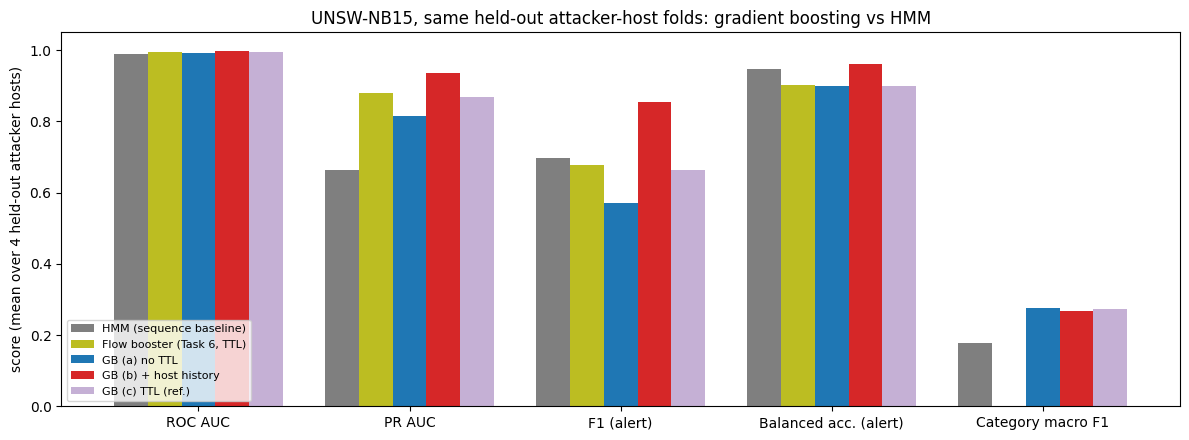

Saved ../results/ids_unsw_gb_comparison.csv and ../results/ids_unsw_gb_vs_hmm.png


In [33]:
plot_models = ["HMM", "Independent-flow booster", "GB (a) per-flow, no TTL", "GB (b) per-flow + host history, no TTL", TTL_VARIANT]
plot_metrics = {"ROC AUC": "roc_auc", "PR AUC": "average_precision", "F1 (alert)": "f1",
                "Balanced acc. (alert)": "balanced_accuracy", "Category macro F1": "category_macro_f1"}
plot_frame = held_out.loc[plot_models, list(plot_metrics.values())].rename(columns={v: k for k, v in plot_metrics.items()})
plot_frame.index = ["HMM (sequence baseline)", "Flow booster (Task 6, TTL)", "GB (a) no TTL", "GB (b) + host history", "GB (c) TTL (ref.)"]
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_frame.T.plot.bar(ax=ax, rot=0, width=0.8, color=["#7f7f7f", "#bcbd22", "#1f77b4", "#d62728", "#c5b0d5"])
ax.set(ylim=(0, 1.05), ylabel="score (mean over 4 held-out attacker hosts)",
       title="UNSW-NB15, same held-out attacker-host folds: gradient boosting vs HMM")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("../results/ids_unsw_gb_vs_hmm.png", dpi=130)
plt.show()
gb_comparison.round(4).to_csv("../results/ids_unsw_gb_comparison.csv")
print("Saved ../results/ids_unsw_gb_comparison.csv and ../results/ids_unsw_gb_vs_hmm.png")

**Adopting the winners.** From here on, `ids_unsw` uses the primary GB **detector** for live alerts and the primary GB **classifier** for category names. That covers the risk tiers, host ranking and claims table in Tasks 12–13. The Task 8 anomaly detector stays as the **novelty detector**: it is trained only on normal traffic, so it is the evidence for unseen attacks and anomalies. The supervised GB detector only knows the attack types in shard 1. The "before" objects are kept so Task 12 can show both.

In [34]:
# keep the "before" objects, then switch the downstream steps (Task 12 risk tiers, host ranking, claims) to the winners
task11_pred, task11_attack_score, category_summary_task11 = later_pred, later_attack_score, dict(category_summary)
latency_summary_anomaly = dict(latency_summary)
batch_table["alert_anomaly"] = batch_table["alert"]                 # Task 8 anomaly alerts (still the novelty detector)
batch_table["alert"] = gb_minute_score >= GB_LIVE_THRESHOLD          # primary detector alerts
category_model = shard_models[PRIMARY_CLASSIFIER]
later_pred, later_attack_score, later_proba = shard_outputs[PRIMARY_CLASSIFIER]
primary_shard_summary = flow_level_summary(truth_later, later_pred, later_attack_score)
category_summary = {key: primary_shard_summary[key] for key in category_summary_task11}
latency_summary = latency_summary_gb
assert np.array_equal(batch_table["alert"].sum(), windows_live["alert_gb"].sum())
print("Downstream steps now use:", {"alerts": PRIMARY_DETECTOR, "category names": PRIMARY_CLASSIFIER})
display(pd.DataFrame({"before (Task 11 classifier)": category_summary_task11, "after (primary classifier)": category_summary}).round(4))

Downstream steps now use: {'alerts': 'GB (b) per-flow + host history, no TTL', 'category names': 'GB (a) per-flow, no TTL'}


,before (Task 11 classifier),after (primary classifier)
accuracy,0.9560,0.9580
macro_f1,0.4645,0.4778
attack_vs_normal_roc_auc,0.9979,0.9988
attack_vs_normal_pr_auc,0.9881,0.9935
attack_precision,0.9000,0.9049
attack_recall,0.9992,0.9987


**What we found.**
- Gradient boosting is the better classifier and detector on UNSW-NB15. On the HMM's own held-out-host folds, the primary detector (b) beats the HMM on PR AUC, F1, false alarms and balanced accuracy, and the primary classifier (a) beats it on category macro F1 and balanced accuracy. The HMM stays in Task 6 as the **sequence baseline** the problem statement asks for.
- The live replay result for the GB detector is very high because shards 2–4 are attacked by the same 4 machines and attack types it was trained on. It shows that a supervised model is very strong on known attacks. It does **not** show novelty detection, which is still the anomaly detector's job (Tasks 7–8).

## Task 12 — Risk Tiers and Decision Support for UNSW Alerts
*Source: IDS_Final §12 risk policy, extended to UNSW categories.* Each live alert gets the most common attack category the classifier predicts among its flows, or **Unknown attack** if the classifier sees only normal flows. Alerts come from the **primary GB detector** and categories from the **primary GB classifier** (Task 11b). The same table is also computed for the earlier setup (Task 8 anomaly alerts + Task 11 classifier) so the change is visible. Tiers:
- **Low:** no alert · **Medium:** Reconnaissance, Analysis, Fuzzers (probing / scanning)
- **High:** DoS, Generic, Unknown attack (disruption or unexplained anomaly)
- **Critical:** Exploits, Backdoors, Shellcode, Worms (code execution / control of a host)

Hosts are then ranked by their risk so an analyst knows where to look first.

In [35]:
UNSW_RISK = {"Reconnaissance": "Medium", "Analysis": "Medium", "Fuzzers": "Medium",
             "DoS": "High", "Generic": "High", "Unknown attack": "High",
             "Exploits": "Critical", "Backdoors": "Critical", "Shellcode": "Critical", "Worms": "Critical"}
RISK_ORDER = ["Low", "Medium", "High", "Critical"]
RISK_WEIGHT = {"Low": 0, "Medium": 1, "High": 2, "Critical": 3}

_, stream_window = host_time_windows(stream)       # window id of every streamed flow (same order as batch_table)
true_category = (pd.DataFrame({"window": stream_window, "cat": later["attack_cat"].to_numpy()})
                 .query("cat != 'Normal'").groupby("window")["cat"].agg(lambda s: s.value_counts().index[0]))
batch_table["true_category"] = pd.Series(true_category).reindex(np.arange(len(batch_table))).fillna("Normal").to_numpy()


def assign_risk(table, alert, predictions):
    table = table.copy()
    flow_frame = pd.DataFrame({"window": stream_window, "pred": predictions})
    named = flow_frame[flow_frame["pred"] != "Normal"].groupby("window")["pred"].agg(lambda s: s.value_counts().index[0])
    table["alert"] = np.asarray(alert)
    table["named_category"] = pd.Series(named).reindex(np.arange(len(table))).fillna("Unknown attack").to_numpy()
    table["risk_tier"] = np.where(table["alert"], table["named_category"].map(UNSW_RISK), "Low")
    high = table["risk_tier"].isin(["High", "Critical"])
    hit = table["alert"] & (table["attack"] == 1)
    summary = {"attack_minutes_High_or_Critical_%": 100 * high[table["attack"] == 1].mean(),
               "benign_minutes_High_or_Critical_%": 100 * high[table["attack"] == 0].mean(),
               "named_alerts_category_correct_%": 100 * np.mean(table.loc[hit, "named_category"] == table.loc[hit, "true_category"])}
    return table, summary


# before: Task 8 anomaly alerts + Task 11 classifier; after: primary GB detector alerts + primary GB classifier (Task 11b)
risk_table_before, risk_summary_before = assign_risk(batch_table, batch_table["alert_anomaly"], task11_pred)
batch_table, risk_summary = assign_risk(batch_table, batch_table["alert"], later_pred)

tier_table = pd.crosstab(batch_table["true_category"], pd.Categorical(batch_table["risk_tier"], categories=RISK_ORDER), dropna=False)
tier_table.columns.name = "risk tier"
print("Host-minutes of shards 2-4: true main category x assigned risk tier (primary GB detector + classifier)")
display(tier_table)
display(pd.DataFrame({"before (anomaly alerts + Task 11 classifier)": risk_summary_before,
                      "after (primary GB detector + classifier)": risk_summary}).round(1))

Host-minutes of shards 2-4: true main category x assigned risk tier (primary GB detector + classifier)


risk tier,Low,Medium,High,Critical
true_category,,,,
Analysis,0,3,4,6
DoS,0,8,1,6
Exploits,1,367,106,1192
Fuzzers,0,485,4,25
Generic,2,7,347,1
Normal,15687,4,21,7
Reconnaissance,0,127,1,44


,before (anomaly alerts + Task 11 classifier),after (primary GB detector + classifier)
attack_minutes_High_or_Critical_%,47.8,63.5
benign_minutes_High_or_Critical_%,5.6,0.2
named_alerts_category_correct_%,72.4,77.2


In [36]:
def rank_hosts(table):
    table = table.assign(risk_points=table["risk_tier"].map(RISK_WEIGHT))
    ranking = table.groupby("srcip").agg(
        risk_points=("risk_points", "sum"), alerts=("alert", "sum"),
        critical_alerts=("risk_tier", lambda s: int((s == "Critical").sum())),
        active_minutes=("minute", "size"),
        top_category=("named_category", lambda s: s[s != "Unknown attack"].value_counts().index[0]
                      if (s != "Unknown attack").any() else "Unknown attack"),
        first_seen=("first", "min"), true_attacker=("attack", "max")).sort_values("risk_points", ascending=False)
    ranking["alert_rate_%"] = 100 * ranking["alerts"] / ranking["active_minutes"]
    ranking["first_seen"] = pd.to_datetime(ranking["first_seen"], unit="s")
    return ranking


host_ranking_before = rank_hosts(risk_table_before)
attackers_in_top4_before = int(host_ranking_before.head(4)["true_attacker"].sum())
host_ranking = rank_hosts(batch_table)
print("Host risk ranking for shards 2-4 with the primary models (true_attacker is shown only to check the ranking):")
display(host_ranking.head(10))
attackers_in_top4 = int(host_ranking.head(4)["true_attacker"].sum())
gap_to_first_benign = (host_ranking.loc[host_ranking["true_attacker"] == 1, "risk_points"].min()
                       / host_ranking.loc[host_ranking["true_attacker"] == 0, "risk_points"].max())
print(f"Attacker hosts among the top 4 ranked hosts: {attackers_in_top4}/4 (before: {attackers_in_top4_before}/4); "
      f"lowest attacker has {gap_to_first_benign:.1f}x the risk points of the highest benign host")

Host risk ranking for shards 2-4 with the primary models (true_attacker is shown only to check the ranking):


,risk_points,alerts,critical_alerts,active_minutes,top_category,first_seen,true_attacker,alert_rate_%
srcip,,,,,,,,
175.45.176.3,1471,684,315,685,Exploits,2015-02-18 00:23:28,1,99.854015
175.45.176.1,1443,687,309,687,Exploits,2015-02-18 00:23:35,1,100.000000
175.45.176.0,1438,686,309,687,Exploits,2015-02-18 00:23:28,1,99.854440
175.45.176.2,1409,685,345,686,Exploits,2015-02-18 00:23:31,1,99.854227
149.171.126.15,6,2,2,71,Exploits,2015-02-18 01:08:59,0,2.816901
59.166.0.1,6,3,0,965,Exploits,2015-01-22 19:44:04,0,0.310881
59.166.0.5,6,3,0,965,Exploits,2015-01-22 19:44:02,0,0.310881
59.166.0.6,6,3,0,965,Exploits,2015-01-22 19:44:03,0,0.310881
59.166.0.0,4,2,0,965,Exploits,2015-01-22 19:44:02,0,0.207254


Attacker hosts among the top 4 ranked hosts: 4/4 (before: 4/4); lowest attacker has 234.8x the risk points of the highest benign host


In [37]:
batch_check = stream.iloc[:5000]
timings = []
for _ in range(3):
    start = time.perf_counter()
    table, check_window = host_time_windows(batch_check)
    percentile_score(live_scorers, live_reference, host_matrix(table, NO_TTL_FEATURES), LIVE_SCORE)     # novelty detector (Task 8)
    history_check = host_history_features(batch_check)
    detector_score = 1 - shard_models[PRIMARY_DETECTOR].predict_proba(VARIANT_FEATURES[PRIMARY_DETECTOR](batch_check, history_check))[:, 0]
    pd.Series(detector_score).groupby(check_window).max() >= GB_LIVE_THRESHOLD                          # primary detector alerts
    category_model.predict_proba(VARIANT_FEATURES[PRIMARY_CLASSIFIER](batch_check, history_check))     # primary classifier
    timings.append(time.perf_counter() - start)
BATCH_THROUGHPUT = len(batch_check) / np.median(timings)
print(f"Anomaly detector + primary GB detector + primary classifier on a 5,000-flow batch: {BATCH_THROUGHPUT:,.0f} flows/second")

Anomaly detector + primary GB detector + primary classifier on a 5,000-flow batch: 18,200 flows/second


**Limitations.**
- NSL-KDD: R2L/U2R stay weak (very few, mostly unseen training examples), and it has no order for an HMM (ids_nsl_kdd T19, T21).
- UNSW-NB15: only 4 attacker hosts, so host-level results have high variance; TTL is a testbed artefact (we report without it); false alarms drift above the 5% budget on later days.
- The live replay uses recorded flows; packet capture and flow extraction are not included in the throughput.
- The primary GB detector is supervised. Its near-perfect live replay uses the same 4 attacker hosts and attack types it was trained on, so unseen-attack claims rest on the anomaly detector and the held-out-host folds, not on the live GB number.

## Task 14 — Save Results
*Source: Repo (outputs saved to `../results/`).*

In [39]:
summary_unsw = {
    "hmm_unsw": hmm_summary.round(4).reset_index().to_dict(orient="records"),
    "category_hmm": stage_results.groupby("model")[["accuracy", "macro_f1"]].mean().round(4).reset_index().to_dict(orient="records"),
    "host_minute": ttl_comparison.round(4).reset_index().to_dict(orient="records"),
    "host_minute_shards": shard_compare.round(4).to_dict(orient="records"),
    "live_replay": live_table.round(4).to_dict(orient="records"),
    "live_latency": {k: float(v) for k, v in latency_summary_anomaly.items()},          # Task 8 anomaly detector
    "throughput_flows_per_second": THROUGHPUT,
    "clustering": {k: float(v) for k, v in cluster_metrics.items()},
    "alert_triage": {k: float(v) for k, v in triage_summary.items()},
    "flow_novelty_weak": novelty_summary.round(4).to_dict(orient="records"),
    "transfer": transfer_table.round(4).to_dict(orient="records"),
    "category_model": {k: float(v) for k, v in category_summary_task11.items()},      # Task 11 model, as first reported
    "risk": {k: float(v) for k, v in risk_summary_before.items()},                     # anomaly alerts + Task 11 model
    "attackers_in_top4": attackers_in_top4_before,
    "gb": {
        "primary_classifier": PRIMARY_CLASSIFIER, "primary_detector": PRIMARY_DETECTOR,
        "settings": {PRIMARY_CLASSIFIER: chosen_setting(PRIMARY_CLASSIFIER), PRIMARY_DETECTOR: chosen_setting(PRIMARY_DETECTOR)},
        "selection_rule": "validation hosts only: classifier = best validation macro F1, detector = best validation PR AUC; TTL variant not eligible",
        "held_out_hosts": held_out.drop(columns=["protocol", "unit"]).round(4).reset_index().to_dict(orient="records"),
        "validation": validation_compare.round(4).reset_index().to_dict(orient="records"),
        "per_category_held_out": per_class_flat.reset_index().to_dict(orient="records"),
        "shards_2_4": shard_compare_gb.round(4).reset_index().to_dict(orient="records"),
        "live_threshold": float(GB_LIVE_THRESHOLD),
        "live_detector": {k: (float(v) if not isinstance(v, str) else v) for k, v in live_gb_row.items()},
        "fold_runtime_seconds": round(GB_SECONDS, 1),
    },
    "primary_downstream": {
        "category_model": {"before": {k: float(v) for k, v in category_summary_task11.items()},
                           "after": {k: float(v) for k, v in category_summary.items()}},
        "live_latency": {"before": {k: float(v) for k, v in latency_summary_anomaly.items()},
                         "after": {k: float(v) for k, v in latency_summary.items()}},
        "risk": {"before": {k: float(v) for k, v in risk_summary_before.items()},
                 "after": {k: float(v) for k, v in risk_summary.items()}},
        "attackers_in_top4": {"before": attackers_in_top4_before, "after": attackers_in_top4},
        "batch_throughput_flows_per_second_after": round(BATCH_THROUGHPUT, 0),
    },
    "runtime_seconds": round(time.time() - RUN_STARTED, 1),
}
with open("../results/ids_unsw_summary.json", "w") as handle:
    json.dump(summary_unsw, handle, indent=2, default=str)
claims_table.to_csv("../results/ids_unsw_claims_coverage.csv", index=False)
alerts_live.to_csv("../results/ids_unsw_live_alerts.csv", index=False)
host_ranking.to_csv("../results/ids_unsw_host_risk_ranking.csv")
print("Saved results to ../results/ | total runtime", summary_unsw["runtime_seconds"], "s")

Saved results to ../results/ | total runtime 669.6 s
